# Portfolio Optimization in Statistical Arbitrage: A Deep Dive

Companion notebook to the Medium article by Federico M. Glancszpigel (Avaq Research).

Nineteen position-sizing methods are applied to the same signals on two stat-arb books in US large caps, 2014–2026:

- **Pairs book**: monthly Engle-Granger cointegration formation within GICS sectors.
- **PCA-residual book**: Avellaneda & Lee (2010) residual mean reversion on 15 eigenportfolios.

Methods: 1/N, inverse vol, signal-weighted, ERC, max diversification, min-var (Ledoit-Wolf, nonlinear shrinkage, RMT-denoised), max Sharpe, half Kelly, factor-neutral max Sharpe, HRP, HERC, NCO, min CVaR, meta-labeling (GBM), random forest μ, elastic net μ, and an end-to-end Sharpe-trained neural net. Every method gets the same 10% volatility-target overlay and the same cost model.

Everything is walk-forward: information up to the close of day *t* sets the position held from *t* to *t+1*.

**Runtime:** about one hour on two CPU cores. The machine-learning step on the PCA-residual book is the slowest part.

**Data:** `data/statarb_prices.csv` (split- and dividend-adjusted daily closes from Yahoo Finance, 209 stocks plus 7 factor ETFs). If the file is missing, the notebook downloads it again; a fresh download can differ slightly from the published file.

In [1]:
import os, warnings
os.makedirs("data", exist_ok=True); os.makedirs("out", exist_ok=True); os.makedirs("fig", exist_ok=True)
warnings.filterwarnings("ignore")
# pip install numpy pandas scipy scikit-learn statsmodels cvxpy highspy autograd yfinance matplotlib pyarrow

## 1. Universe
Current S&P 500 constituents with history since 2011, by GICS sector. Membership is as of 2026, so the universe has survivorship bias.

In [2]:
"""Universe: current S&P 500 large caps with continuous history since 2011, by GICS sector.
Survivorship bias is acknowledged: membership is as of 2026, not point-in-time."""

UNIVERSE = {
    "Information Technology": ["AAPL","MSFT","ORCL","CSCO","IBM","INTC","QCOM","TXN","ADI","AMAT",
                               "LRCX","KLAC","MU","ADBE","CRM","INTU","ACN","HPQ","GLW","APH","ADSK","NVDA","AMD","MCHP","CTSH"],
    "Health Care": ["JNJ","PFE","MRK","ABT","BMY","LLY","AMGN","GILD","MDT","SYK","BDX","BSX",
                    "UNH","CI","ELV","HUM","TMO","DHR","BAX","ZBH","CAH","MCK","REGN","VRTX","BIIB"],
    "Financials": ["JPM","BAC","WFC","C","GS","MS","USB","PNC","TFC","BK","STT","SCHW",
                   "AXP","COF","MET","PRU","AFL","ALL","TRV","CB","AIG","MMC","AON","BLK","CME"],
    "Consumer Discretionary": ["AMZN","HD","LOW","MCD","SBUX","NKE","TJX","ROST","BKNG","GPC",
                               "F","YUM","ORLY","AZO","MAR","DRI","EBAY","BBY","TGT","HAS"],
    "Consumer Staples": ["PG","KO","PEP","WMT","COST","CL","KMB","GIS","K","HSY","MDLZ",
                         "MO","CLX","SYY","KR","CPB","CAG","SJM","CHD","ADM"],
    "Industrials": ["GE","HON","MMM","CAT","DE","UNP","CSX","NSC","UPS","FDX","LMT","GD",
                    "NOC","RTX","EMR","ETN","ITW","PH","ROK","DOV","CMI","PCAR","WM","RSG","SWK"],
    "Energy": ["XOM","CVX","COP","EOG","OXY","SLB","HAL","DVN","APA","MRO","HES","VLO","MPC","PSX","BKR","OKE","WMB","KMI"],
    "Utilities": ["NEE","DUK","SO","D","AEP","EXC","SRE","XEL","ED","PEG","WEC","ES",
                  "DTE","ETR","PPL","AEE","CMS","CNP","NI","EIX"],
    "Materials": ["LIN","APD","ECL","SHW","DD","NEM","FCX","NUE","PPG","IP","BALL","VMC","MLM","IFF","AVY"],
    "Real Estate": ["PLD","AMT","CCI","SPG","PSA","EQR","AVB","WELL","VTR","BXP","O","ESS","MAA","EXR","HST"],
    "Communication Services": ["GOOGL","VZ","T","CMCSA","DIS","NFLX","EA","TTWO","OMC","IPG"],
}
FACTOR_ETFS = ["SPY","IWM","IVE","IVW","MTUM","QUAL","USMV"]
SECTOR_OF = {t: s for s, ts in UNIVERSE.items() for t in ts}
TICKERS = list(SECTOR_OF)


## 2. Data
Loads the published price file, or downloads from Yahoo Finance if it isn't there.

In [3]:
import pandas as pd, numpy as np
if os.path.exists("data/statarb_prices.csv"):
    px_raw = pd.read_csv("data/statarb_prices.csv", index_col=0, parse_dates=True)
else:
    import yfinance as yf
    d = yf.download(TICKERS + FACTOR_ETFS, start="2010-06-01", end="2026-11-13", auto_adjust=True, progress=False)
    px_raw = d["Close"].dropna(axis=1, how="all")
px_raw.to_parquet("data/px.parquet")
print(px_raw.shape, px_raw.index.min().date(), px_raw.index.max().date())

(4140, 216) 2010-06-01 2026-11-12


## 3. Covariance estimators and allocation primitives
Ledoit-Wolf, analytical nonlinear shrinkage (Ledoit & Wolf 2020), RMT denoising; long-only min-variance and tangency by active-set elimination; ERC by cyclical coordinate descent; HRP, HERC, NCO, max diversification and min CVaR.

In [4]:
"""Allocation methods. All operate in 'signed position space': each column is a position return
s_i * r_pair_i, so long-only weights (w >= 0) are the natural constraint. Inputs are estimated
strictly on data up to and including day t."""
import numpy as np
from scipy.cluster.hierarchy import linkage, fcluster, to_tree
from scipy.spatial.distance import squareform
from sklearn.covariance import LedoitWolf
from sklearn.metrics import silhouette_score
from sklearn.cluster import KMeans
import cvxpy as cp


# ---------- covariance estimators ----------
def cov_lw(X):
    return LedoitWolf().fit(X).covariance_


def cov_nls(X):
    """Ledoit & Wolf (2020) analytical nonlinear shrinkage, demeaned data (n = T-1)."""
    X = X - X.mean(0)
    n, p = X.shape[0] - 1, X.shape[1]
    S = X.T @ X / n
    lam, u = np.linalg.eigh(S)
    lam = np.maximum(lam, 1e-12)
    h = n ** (-1 / 3)
    L = np.tile(lam[:, None], (1, p))          # L[i,j] = lam_i
    H = h * L.T                                 # H[i,j] = h lam_j
    x = (L - L.T) / H
    ft = (3 / 4 / np.sqrt(5)) * np.mean(np.maximum(1 - x ** 2 / 5, 0) / H, axis=1)
    with np.errstate(divide="ignore", invalid="ignore"):
        Hf = (-3 / 10 / np.pi) * x + (3 / 4 / np.sqrt(5) / np.pi) * (1 - x ** 2 / 5) * \
             np.log(np.abs((np.sqrt(5) - x) / (np.sqrt(5) + x)))
    edge = np.isclose(np.abs(x), np.sqrt(5)) | ~np.isfinite(Hf)
    Hf[edge] = ((-3 / 10 / np.pi) * x)[edge]
    Hft = np.mean(Hf / H, axis=1)
    c = p / n
    d = lam / ((np.pi * c * lam * ft) ** 2 + (1 - c - np.pi * c * lam * Hft) ** 2)
    return u @ np.diag(d) @ u.T


def cov_rmt(X):
    """Constant-residual-eigenvalue denoising of the correlation matrix (Marchenko-Pastur edge, sigma^2=1)."""
    T, N = X.shape
    sd = X.std(0, ddof=1)
    C = np.corrcoef(X, rowvar=False)
    lam, v = np.linalg.eigh(C)
    lmax = (1 + np.sqrt(N / T)) ** 2
    noise = lam < lmax
    if noise.sum() > 0 and noise.sum() < N:
        lam = lam.copy(); lam[noise] = lam[noise].mean()
    C2 = v @ np.diag(lam) @ v.T
    d = np.sqrt(np.diag(C2)); C2 = C2 / np.outer(d, d)
    return C2 * np.outer(sd, sd)


# ---------- solvers ----------
def lo_minvar(S):
    """Long-only, fully invested minimum variance via active-set elimination."""
    n = len(S); act = np.arange(n)
    while True:
        Si = np.linalg.pinv(S[np.ix_(act, act)])
        w = Si @ np.ones(len(act)); w /= w.sum()
        if (w >= -1e-12).all():
            out = np.zeros(n); out[act] = np.maximum(w, 0); return out / out.sum()
        act = act[np.arange(len(act)) != np.argmin(w)]


def lo_maxsharpe(S, mu):
    """Long-only tangency: min y'Sy s.t. mu'y = 1, y >= 0, w = y / sum(y). Active-set elimination."""
    n = len(S); act = np.where(mu > 0)[0]
    if len(act) == 0:
        return np.zeros(n)
    while len(act):
        y = np.linalg.pinv(S[np.ix_(act, act)]) @ mu[act]
        if (y >= -1e-12).all():
            out = np.zeros(n); out[act] = np.maximum(y, 0)
            return out / out.sum() if out.sum() > 0 else out
        act = act[np.arange(len(act)) != np.argmin(y)]
    return np.zeros(n)


def erc(S, iters=1000, tol=1e-10):
    """Equal risk contribution via cyclical coordinate descent on 0.5 y'Sy - (1/n) sum log y
    (Griveau-Billion, Richard & Roncalli 2013)."""
    n = len(S); b = 1.0 / n
    y = 1 / np.sqrt(np.diag(S)); y /= np.sqrt(y @ S @ y)
    for _ in range(iters):
        y_old = y.copy()
        for i in range(n):
            c = S[i] @ y - S[i, i] * y[i]
            y[i] = (-c + np.sqrt(c * c + 4 * S[i, i] * b)) / (2 * S[i, i])
        if np.abs(y - y_old).max() < tol * np.abs(y).max():
            break
    return y / y.sum()


def ivp(S):
    w = 1 / np.diag(S); return w / w.sum()


def corr_dist(S):
    d = np.sqrt(np.diag(S)); C = np.clip(S / np.outer(d, d), -1, 1)
    D = np.sqrt(np.clip((1 - C) / 2, 0, None)); np.fill_diagonal(D, 0)
    return C, D


def hrp(S):
    n = len(S)
    if n < 3:
        return ivp(S)
    _, D = corr_dist(S)
    Z = linkage(squareform(D, checks=False), "single")
    order = list(to_tree(Z).pre_order())
    w = np.ones(n); clusters = [order]
    while clusters:
        nxt = []
        for c in clusters:
            if len(c) < 2:
                continue
            h = len(c) // 2; c1, c2 = c[:h], c[h:]
            v1 = cvar(S, c1); v2 = cvar(S, c2); a = 1 - v1 / (v1 + v2)
            w[c1] *= a; w[c2] *= 1 - a; nxt += [c1, c2]
        clusters = nxt
    return w / w.sum()


def cvar(S, idx):
    Ss = S[np.ix_(idx, idx)]; w = ivp(Ss); return w @ Ss @ w


def n_clusters_silhouette(D, Z, kmax):
    best, bk = -1, 1
    for k in range(2, kmax + 1):
        lab = fcluster(Z, k, "maxclust")
        if len(set(lab)) < 2 or len(set(lab)) >= len(lab):
            continue
        s = silhouette_score(D, lab, metric="precomputed")
        if s > best:
            best, bk = s, k
    return bk


def herc(S):
    """Raffinot (2018) HERC, variance risk measure; k chosen by silhouette (instead of gap statistic)."""
    n = len(S)
    if n < 4:
        return ivp(S)
    _, D = corr_dist(S)
    Z = linkage(squareform(D, checks=False), "ward")
    k = n_clusters_silhouette(D, Z, min(10, n - 1))
    lab = fcluster(Z, k, "maxclust")
    root = to_tree(Z)
    w = np.zeros(n)

    def leaves(node): return node.pre_order()

    def alloc(node, wt):
        lv = leaves(node)
        if len(set(lab[lv])) == 1 or node.is_leaf():
            sub = ivp(S[np.ix_(lv, lv)]); w[lv] = wt * sub; return
        l, r = node.get_left(), node.get_right()
        vl, vr = cvar(S, leaves(l)), cvar(S, leaves(r))
        a = 1 - vl / (vl + vr)
        alloc(l, wt * a); alloc(r, wt * (1 - a))
    alloc(root, 1.0)
    return w / w.sum()


def nco(S):
    """Lopez de Prado (2019) Nested Clustered Optimization with long-only min-variance at both levels.
    Deviation: clusters from Ward hierarchical clustering on the correlation distance with k chosen by
    silhouette (the paper uses KMeans with silhouette); same selection rule, much cheaper."""
    n = len(S)
    if n < 4:
        return lo_minvar(S)
    _, D = corr_dist(S)
    Z = linkage(squareform(D, checks=False), "ward")
    k = n_clusters_silhouette(D, Z, min(10, n - 1))
    lab = fcluster(Z, k, "maxclust")
    ks = sorted(set(lab))
    Wc = np.zeros((n, len(ks)))
    for j, kk in enumerate(ks):
        idx = np.where(lab == kk)[0]
        Wc[idx, j] = lo_minvar(S[np.ix_(idx, idx)])
    Sc = Wc.T @ S @ Wc
    wc = lo_minvar(Sc)
    return Wc @ wc


def maxdiv(S):
    """Choueifaty-Coignard maximum diversification = tangency with mu = sigma."""
    return lo_maxsharpe(S, np.sqrt(np.diag(S)))


def min_cvar(X, alpha=0.95):
    """Rockafellar-Uryasev min CVaR(95%) on the historical scenarios, long-only, fully invested."""
    T, n = X.shape
    w = cp.Variable(n, nonneg=True); z = cp.Variable(T, nonneg=True); v = cp.Variable()
    loss = -X @ w
    prob = cp.Problem(cp.Minimize(v + cp.sum(z) / ((1 - alpha) * T)),
                      [z >= loss - v, cp.sum(w) == 1])
    try:
        prob.solve(solver="HIGHS")
        ww = np.maximum(np.asarray(w.value).ravel(), 0)
        return ww / ww.sum()
    except Exception:
        return np.ones(n) / n


## 4. Pairs book: formation and signals
Monthly formation on 252 days. Entry |z| > 1.5, exit |z| < 0.25, stop |z| > 4.

In [5]:
"""Pair formation and signal engine. Walk-forward, no lookahead.

Formation: at each month-end t0, using the trailing 252 trading days (ending at t0 inclusive):
  - candidate pairs within GICS sector, return correlation >= 0.4
  - Engle-Granger: OLS log(A) = a + b log(B); ADF(1 lag, no const) on residuals, t < -3.34 (5%)
  - half-life of residual AR(1) in [5, 60] days; b in [0.2, 5]
  - rank by ADF t; take up to 40 pairs, each stock in at most 3 pairs, at most 8 pairs per sector
Trading period: the following month. Spread s = log(A) - a - b log(B), z = s / sd(formation residual).
Signal at close t applies to the close-to-close return t -> t+1.
Entry |z| > 1.5, exit |z| < 0.25, stop |z| > 4 (no re-entry for that pair in the period).
Open positions in a pair reselected the next month carry over; otherwise they close at period end.
"""
import numpy as np, pandas as pd, pickle

ENTRY, EXIT, STOP = 1.5, 0.25, 4.0
FORM, NPAIRS, MAXSTOCK, MAXSECTOR = 252, 40, 3, 8
ADF_CRIT, HL_MIN, HL_MAX = -3.34, 5, 60


def load_prices():
    px = pd.read_parquet("data/px.parquet").loc["2011-01-03":]
    px = px.ffill(limit=3)
    # DHR 2016-07-05: unadjusted Fortive spin-off artifact (+48% log). Replace with sector median return.
    r = np.log(px).diff()
    hc = [t for t, s in SECTOR_OF.items() if s == "Health Care" and t in px and t != "DHR"]
    d = pd.Timestamp("2016-07-05")
    fix = r.loc[d, hc].median()
    r.loc[d, "DHR"] = fix
    lp = r.fillna(0).cumsum() + np.log(px.bfill().iloc[0])
    lp[px.isna()] = np.nan
    return np.exp(lp)


def adf_t(e):
    de = np.diff(e); el = e[1:-1]; dl = de[:-1]; y = de[1:]
    X = np.column_stack([el, dl])
    coef, *_ = np.linalg.lstsq(X, y, rcond=None)
    res = y - X @ coef
    s2 = res @ res / (len(y) - 2)
    cov = s2 * np.linalg.inv(X.T @ X)
    return coef[0] / np.sqrt(cov[0, 0])


def form_pairs(lpx, rets):
    """lpx, rets: formation-window DataFrames (no NaN columns)."""
    cands = []
    corr = rets.corr()
    for sec in set(SECTOR_OF.values()):
        ts = [t for t in lpx.columns if SECTOR_OF.get(t) == sec]
        for i in range(len(ts)):
            for j in range(i + 1, len(ts)):
                a, b = ts[i], ts[j]
                if corr.loc[a, b] < 0.4:
                    continue
                y, x = lpx[a].values, lpx[b].values
                X = np.column_stack([np.ones_like(x), x])
                (al, be), *_ = np.linalg.lstsq(X, y, rcond=None)
                if not (0.2 <= be <= 5):
                    continue
                e = y - al - be * x
                t = adf_t(e)
                if t > ADF_CRIT:
                    continue
                phi = np.polyfit(e[:-1], e[1:], 1)[0]
                if not (0 < phi < 1):
                    continue
                hl = -np.log(2) / np.log(phi)
                if not (HL_MIN <= hl <= HL_MAX):
                    continue
                cands.append(dict(a=a, b=b, alpha=al, beta=be, sd=e.std(ddof=1), hl=hl, adf=t,
                                  corr=corr.loc[a, b], sector=sec))
    cands.sort(key=lambda c: c["adf"])
    sel, cnt, scnt = [], {}, {}
    for c in cands:
        if cnt.get(c["a"], 0) >= MAXSTOCK or cnt.get(c["b"], 0) >= MAXSTOCK or scnt.get(c["sector"], 0) >= MAXSECTOR:
            continue
        sel.append(c)
        cnt[c["a"]] = cnt.get(c["a"], 0) + 1; cnt[c["b"]] = cnt.get(c["b"], 0) + 1
        scnt[c["sector"]] = scnt.get(c["sector"], 0) + 1
        if len(sel) == NPAIRS:
            break
    return sel, len(cands)


def run_pairs():
    px = load_prices()
    stocks = [t for t in SECTOR_OF if t in px.columns]
    px = px[stocks]
    lp = np.log(px)
    R = px.pct_change()
    dates = px.index
    month_ends = dates[dates.to_series().dt.month.diff().shift(-1).fillna(1) != 0]
    month_ends = month_ends[month_ends >= dates[FORM]]
    pos_rows = []           # (date, pair_key, sign, z, days_open) : state at close of date
    registry = {}           # (month_end, a, b) -> pair params
    ncands = {}
    carry = {}              # (a,b) -> (sign, days_open) open at end of previous period
    for k, t0 in enumerate(month_ends[:-1]):
        i0 = dates.get_loc(t0)
        win = slice(i0 - FORM + 1, i0 + 1)
        lw = lp.iloc[win].dropna(axis=1)
        rw = R.iloc[win][lw.columns]
        sel, nc = form_pairs(lw, rw)
        ncands[t0] = nc
        t1 = month_ends[k + 1]
        tdays = dates[(dates > t0) & (dates <= t1)]
        newcarry = {}
        selkeys = {(c["a"], c["b"]) for c in sel}
        for c in sel:
            key = (t0, c["a"], c["b"])
            registry[key] = c
            s = (lp.loc[tdays, c["a"]] - c["alpha"] - c["beta"] * lp.loc[tdays, c["b"]]).values
            z = s / c["sd"]
            sign, dopen = carry.get((c["a"], c["b"]), (0, 0))
            stopped = False
            for j, d in enumerate(tdays):
                zj = z[j]
                if np.isnan(zj):
                    sign = 0
                elif sign != 0:
                    if abs(zj) > STOP:
                        sign, stopped = 0, True
                    elif abs(zj) < EXIT:
                        sign = 0
                    else:
                        dopen += 1
                elif not stopped and ENTRY < abs(zj) < STOP:
                    sign, dopen = (-1 if zj > 0 else 1), 1   # z>0: spread rich -> short spread
                if sign == 0:
                    dopen = 0
                last_day = (j == len(tdays) - 1)
                if last_day and sign != 0:
                    newcarry[(c["a"], c["b"])] = (sign, dopen)
                pos_rows.append((d, key, sign, zj, dopen))
        # positions carried into next month only if reselected next month: handled by lookup next loop;
        # if not reselected they are closed at the last close of this period (state 0 next day by absence)
        carry = newcarry
    pos = pd.DataFrame(pos_rows, columns=["date", "key", "sign", "z", "dopen"])
    # Close at period end any position whose pair is not reselected at that same month-end
    # (the reselection is known at close t1 because formation uses data through t1).
    selby = {}
    for (m, a, b) in registry:
        selby.setdefault(m, set()).add((a, b))
    me_list = list(month_ends)
    nxt = {me_list[i]: me_list[i + 1] for i in range(len(me_list) - 1)}
    m0 = pos.key.map(lambda k: k[0])
    pend = m0.map(nxt)
    is_last = pos.date.values == pend.values
    keep = np.array([(k[1], k[2]) in selby.get(pe, set()) for k, pe in zip(pos.key, pend)])
    pos.loc[is_last & ~keep, "sign"] = 0
    with open("out/pairs.pkl", "wb") as f:
        pickle.dump(dict(pos=pos, registry=registry, ncands=ncands, stocks=stocks), f)
    px.to_parquet("data/px_clean.parquet")
    nsel = pos.groupby("date").key.nunique()
    nopen = pos[pos.sign != 0].groupby("date").size().reindex(nsel.index).fillna(0)
    print("months:", len(ncands), "mean candidates:", np.mean(list(ncands.values())).round(1))
    print("pairs selected/day mean:", nsel.mean().round(1), " open/day mean:", nopen.mean().round(1),
          " days with 0 open:", (nopen == 0).mean().round(3))
    sec = pd.Series([c["sector"] for c in registry.values()]).value_counts(normalize=True).round(3)
    print(sec.to_dict())


In [6]:
run_pairs()

months: 178 mean candidates: 69.1
pairs selected/day mean: 37.1  open/day mean: 15.4  days with 0 open: 0.001
{'Utilities': 0.179, 'Financials': 0.158, 'Industrials': 0.145, 'Information Technology': 0.118, 'Health Care': 0.09, 'Energy': 0.078, 'Consumer Staples': 0.068, 'Consumer Discretionary': 0.056, 'Real Estate': 0.051, 'Materials': 0.05, 'Communication Services': 0.007}


## 5. Position panel for the pairs book
Features at close *t*, labels from *t+1* on.

In [7]:
"""Build the position-level panel (features at close t, labels from t+1 on) and pair stock weights."""
import numpy as np, pandas as pd, pickle

COV_WIN = 126
FACTORS = ["MKT", "SMB", "HML", "MOM", "QUAL", "LVOL"]


def factor_returns():
    p = pd.read_parquet("data/px.parquet")[["SPY", "IWM", "IVE", "IVW", "MTUM", "QUAL", "USMV"]].loc["2011-01-03":]
    r = p.pct_change()
    F = pd.DataFrame({"MKT": r.SPY, "SMB": r.IWM - r.SPY, "HML": r.IVE - r.IVW, "MOM": r.MTUM - r.SPY,
                      "QUAL": r.QUAL - r.SPY, "LVOL": r.USMV - r.SPY})
    return F


def build_panel():
    P = pickle.load(open("out/pairs.pkl", "rb"))
    pos, reg, stocks = P["pos"], P["registry"], P["stocks"]
    px = pd.read_parquet("data/px_clean.parquet")[stocks]
    R = px.pct_change().fillna(0.0)
    dates = R.index
    di = {d: i for i, d in enumerate(dates)}
    si = {s: i for i, s in enumerate(stocks)}
    keys = sorted(reg.keys())
    ki = {k: i for i, k in enumerate(keys)}
    legA = np.array([si[k[1]] for k in keys]); legB = np.array([si[k[2]] for k in keys])
    beta = np.array([reg[k]["beta"] for k in keys])
    wA = 1 / (1 + beta); wB = -beta / (1 + beta)

    pos = pos.copy()
    pos["k"] = pos.key.map(ki); pos["t"] = pos.date.map(di)
    pos = pos.sort_values(["k", "t"])
    pos["absz"] = pos.z.abs()
    pos["dz5"] = (pos.absz - pos.groupby("k").absz.shift(5)).fillna(0.0)
    act = pos[pos.sign != 0].copy()

    Rv = R.values
    T = len(dates)
    # pair daily returns for each active row: needed windows. Compute full pair return series per key lazily.
    rp_cache = {}

    def rpair(k):
        if k not in rp_cache:
            rp_cache[k] = Rv[:, legA[k]] * wA[k] + Rv[:, legB[k]] * wB[k]
        return rp_cache[k]

    F = factor_returns().reindex(dates)
    mvol = F.MKT.rolling(21).std().values * np.sqrt(252)
    rows = []
    for r in act.itertuples():
        k, t, s = r.k, r.t, r.sign
        rp = rpair(k)
        hist = rp[max(0, t - COV_WIN + 1): t + 1]
        c = reg[keys[k]]
        fwd1 = s * rp[t + 1] if t + 1 < T else np.nan
        fwd5 = s * rp[t + 1: t + 6].sum() if t + 5 < T else np.nan
        mu = r.absz * c["sd"] * (1 - np.exp(-1 / c["hl"])) / (1 + c["beta"])
        rows.append((t, k, s, r.z, r.absz, r.dz5, c["hl"], c["adf"], c["corr"], c["beta"], c["sd"],
                     hist.std(ddof=1), mu, r.dopen, mvol[t], fwd1, fwd5))
    cols = ["t", "k", "sign", "z", "absz", "dz5", "hl", "adf", "corr", "beta", "sd_form",
            "vol126", "mu_ou", "dopen", "mkt_vol", "fwd1", "fwd5"]
    panel = pd.DataFrame(rows, columns=cols).sort_values(["t", "k"]).reset_index(drop=True)
    panel["date"] = dates[panel.t]
    out = dict(panel=panel, keys=keys, legA=legA, legB=legB, wA=wA, wB=wB, stocks=stocks,
               dates=dates, R=Rv, F=F)
    pickle.dump(out, open("out/panel.pkl", "wb"))
    print(panel.shape, panel.date.min(), panel.date.max())
    print(panel[["absz", "hl", "vol126", "mu_ou", "fwd1", "fwd5"]].describe().T.round(5))
    # sanity: OU expected 1d return vs realized mean next-day return
    print("mean fwd1 (bps):", (panel.fwd1.mean() * 1e4).round(3), " mean mu_ou (bps):", (panel.mu_ou.mean() * 1e4).round(3))


In [8]:
build_panel()

(57168, 18) 2012-02-01 00:00:00 2026-11-11 00:00:00
          count     mean      std      min      25%      50%      75%  \
absz    57168.0  1.81878  0.76932  0.25008  1.29462  1.74533  2.29453   
hl      57168.0  6.92916  1.54380  5.00137  5.82983  6.59861  7.59214   
vol126  57168.0  0.00719  0.00319  0.00136  0.00511  0.00660  0.00861   
mu_ou   57168.0  0.00438  0.00269  0.00017  0.00246  0.00383  0.00568   
fwd1    57168.0 -0.00000  0.00780 -0.15003 -0.00348  0.00002  0.00356   
fwd5    57116.0 -0.00009  0.01697 -0.16570 -0.00818 -0.00004  0.00819   

             max  
absz     3.99926  
hl      22.61806  
vol126   0.03204  
mu_ou    0.02717  
fwd1     0.11932  
fwd5     0.16283  
mean fwd1 (bps): -0.039  mean mu_ou (bps): 43.808


## 6. PCA-residual book (Avellaneda & Lee 2010)

In [9]:
"""Avellaneda & Lee (2010) PCA residual stat-arb. Daily, no lookahead.
- 252d correlation of standardized returns -> 15 eigenportfolios Q_k = v_k / sigma_i
- 60d regression of each stock on the eigenportfolio returns -> residual; cumulative residual X
- AR(1) on X -> OU params; keep stocks with kappa > 252/30; s-score centered cross-sectionally
- open long s < -1.25, open short s > 1.25; close long s > -0.50, close short s < 0.75
Position = stock minus its factor hedge; position return = residual return of t+1 using betas at t."""
import numpy as np, pandas as pd, pickle

K, PCAWIN, REGWIN = 15, 252, 60
SBO, SSO, SBC, SSC = 1.25, 1.25, 0.75, 0.50


def run_al():
    P = pickle.load(open("out/panel.pkl", "rb"))
    Rv, dates, stocks = P["R"], P["dates"], P["stocks"]
    T, N = Rv.shape
    state = np.zeros(N, int); dopen = np.zeros(N, int)
    Smat = np.full((T, N), np.nan); KAP = np.full((T, N), np.nan); SEQ = np.full((T, N), np.nan)
    rows = []
    hedge = {}      # t -> (betas N x K, Q N x K) to rebuild holdings
    start = PCAWIN
    for t in range(start, T - 1):
        W = Rv[t - PCAWIN + 1: t + 1]
        ok = (np.abs(W).sum(0) > 0)
        mu, sd = W.mean(0), W.std(0, ddof=1)
        sd[sd == 0] = 1
        Z = (W - mu) / sd
        C = np.corrcoef(Z[:, ok], rowvar=False)
        lam, v = np.linalg.eigh(C)
        v = v[:, ::-1][:, :K]
        Q = np.zeros((N, K)); Q[ok] = v / sd[ok][:, None]
        Fw = Rv[t - REGWIN + 1: t + 1] @ Q               # 60 x K factor returns
        Rw = Rv[t - REGWIN + 1: t + 1]
        X = np.column_stack([np.ones(REGWIN), Fw])
        coef, *_ = np.linalg.lstsq(X, Rw, rcond=None)     # (K+1) x N
        eps = Rw - X @ coef
        Xc = np.cumsum(eps, axis=0)
        x0, x1 = Xc[:-1], Xc[1:]
        mx0 = x0.mean(0); mx1 = x1.mean(0)
        with np.errstate(invalid='ignore', divide='ignore'):
            b = ((x0 - mx0) * (x1 - mx1)).sum(0) / ((x0 - mx0) ** 2).sum(0)
        a = mx1 - b * mx0
        zeta = x1 - a - b * x0
        valid = ok & (b > 0) & (b < 1)
        bb = np.where(valid, b, 0.5)
        kappa = -np.log(bb) * 252
        m = a / (1 - bb)
        seq = np.sqrt(zeta.var(0, ddof=1) / (1 - bb ** 2))
        s = (Xc[-1] - m) / seq
        valid &= kappa > 252 / 30
        s_adj = s - np.nanmean(np.where(valid, m / seq, np.nan))  # centered s-score (AL eq. 15 style)
        s_adj = np.where(valid, s_adj, np.nan)
        new = state.copy()
        for i in range(N):
            si = s_adj[i]
            if np.isnan(si):
                new[i] = 0; continue
            if state[i] == 0:
                if si < -SBO: new[i] = 1
                elif si > SSO: new[i] = -1
            elif state[i] == 1 and si > -SSC: new[i] = 0
            elif state[i] == -1 and si < SBC: new[i] = 0
        dopen = np.where(new != 0, np.where(new == state, dopen + 1, 1), 0)
        state = new
        Smat[t] = s_adj; KAP[t] = kappa; SEQ[t] = seq
        beta = coef[1:].T                                   # N x K
        hedge[t] = (beta, Q)
        rnext = Rv[t + 1] - beta @ (Rv[t + 1] @ Q)          # residual return (ex intercept)
        for i in np.where(state != 0)[0]:
            rows.append((t, i, state[i], s_adj[i], kappa[i], seq[i], dopen[i], rnext[i] * state[i]))
    al = pd.DataFrame(rows, columns=["t", "i", "sign", "s", "kappa", "seq", "dopen", "fwd1"])
    al["date"] = dates[al.t]
    pickle.dump(dict(al=al, hedge=hedge, S=Smat, KAP=KAP, SEQ=SEQ), open("out/al.pkl", "wb"))
    n = al.groupby("t").size()
    print("open/day mean", n.mean().round(1), " rows", len(al))
    g = al.groupby(al.date.dt.year).fwd1
    print(pd.DataFrame({"bps": g.mean() * 1e4, "t": g.mean() / g.std() * np.sqrt(g.count())}).round(2))
    ew = al.groupby("t").fwd1.mean()
    print("EW AL daily: ann ret %.3f vol %.3f SR %.2f" % (ew.mean() * 252, ew.std() * np.sqrt(252), ew.mean() / ew.std() * np.sqrt(252)))


In [10]:
run_al()

open/day mean 72.6  rows 271197
       bps     t
date            
2012 -0.30 -0.35
2013  2.41  2.66
2014  2.22  2.83
2015  0.39  0.45
2016  0.53  0.57
2017  0.35  0.46
2018  1.50  1.61
2019  1.93  2.33
2020  3.40  2.54
2021  2.30  2.49
2022 -2.52 -2.51
2023  3.63  3.95
2024 -0.55 -0.55
2025  1.67  1.61
2026  0.80  0.59
EW AL daily: ann ret 0.030 vol 0.032 SR 0.93


## 7. Unified book interface
Signed position pseudo-returns for covariance estimation and stock-level holdings per position.

In [11]:
"""Unified 'book' interface for the pairs book and the Avellaneda-Lee residual book.
Each book exposes, per day t: active positions with features and next-day signed returns, plus
  hist(t, rows)     -> COV_WIN x n matrix of signed position pseudo-returns using day-t hedges
  holdings(t, rows) -> n x N_stocks matrix of stock holdings per unit of each position (signed)
"""
import numpy as np, pandas as pd, pickle

COV_WIN = 126
FEATS = ["absz", "dz5", "hl", "vol126", "mu_ou", "dopen", "mkt_vol"]


class PairsBook:
    name = "pairs"

    def __init__(self):
        P = pickle.load(open("out/panel.pkl", "rb"))
        self.R, self.dates, self.stocks, self.F = P["R"], P["dates"], P["stocks"], P["F"].fillna(0.0)
        self.legA, self.legB, self.wA, self.wB = P["legA"], P["legB"], P["wA"], P["wB"]
        p = P["panel"].copy()
        p["pid"] = p.k
        self.panel = p[["t", "pid", "sign"] + FEATS + ["fwd1", "fwd5"]].reset_index(drop=True)

    def hist(self, t, rows):
        W = self.R[t - COV_WIN + 1: t + 1]
        k = rows.pid.values; s = rows.sign.values
        return (W[:, self.legA[k]] * self.wA[k] + W[:, self.legB[k]] * self.wB[k]) * s

    def holdings(self, t, rows):
        k = rows.pid.values; s = rows.sign.values
        H = np.zeros((len(rows), self.R.shape[1]))
        H[np.arange(len(k)), self.legA[k]] += self.wA[k] * s
        H[np.arange(len(k)), self.legB[k]] += self.wB[k] * s
        return H


class ALBook:
    name = "al"

    def __init__(self):
        P = pickle.load(open("out/panel.pkl", "rb"))
        self.R, self.dates, self.stocks, self.F = P["R"], P["dates"], P["stocks"], P["F"].fillna(0.0)
        A = pickle.load(open("out/al.pkl", "rb"))
        self.hedge = A["hedge"]
        al = A["al"].copy()
        S = A["S"]
        T = len(self.dates)
        Rv = self.R
        mvol = self.F.MKT.rolling(21).std().values * np.sqrt(252)
        al["absz"] = al.s.abs()
        prev = np.abs(S[np.maximum(al.t.values - 5, 0), al.i.values])
        al["dz5"] = np.nan_to_num(al.absz.values - prev, nan=0.0)
        al["hl"] = 252 * np.log(2) / al.kappa
        b = np.exp(-al.kappa / 252)
        al["mu_ou"] = al.absz * al.seq * (1 - b)
        al["mkt_vol"] = mvol[al.t.values]
        vol126 = np.empty(len(al)); fwd5 = np.full(len(al), np.nan)
        for t, g in al.groupby("t").groups.items():
            g = np.asarray(g)
            beta, Q = self.hedge[t]
            i = al.i.values[g]
            W = Rv[t - COV_WIN + 1: t + 1]
            res = W[:, i] - (W @ Q) @ beta[i].T
            vol126[g] = res.std(0, ddof=1)
            if t + 5 < T:
                Wf = Rv[t + 1: t + 6]
                rf = Wf[:, i] - (Wf @ Q) @ beta[i].T
                fwd5[g] = rf.sum(0) * al.sign.values[g]
        al["vol126"] = vol126; al["fwd5"] = fwd5
        al["pid"] = al.i
        self.panel = al[["t", "pid", "sign"] + FEATS + ["fwd1", "fwd5"]].sort_values(["t", "pid"]).reset_index(drop=True)

    def hist(self, t, rows):
        beta, Q = self.hedge[t]
        i = rows.pid.values
        W = self.R[t - COV_WIN + 1: t + 1]
        return (W[:, i] - (W @ Q) @ beta[i].T) * rows.sign.values

    def holdings(self, t, rows):
        beta, Q = self.hedge[t]
        i = rows.pid.values; s = rows.sign.values
        H = -(beta[i] @ Q.T)                      # n x N hedge part
        H[np.arange(len(i)), i] += 1.0
        return H * s[:, None]


def get_book(name):
    return PairsBook() if name == "pairs" else ALBook()


## 8. Walk-forward machine learning
Models retrain every January on an expanding window, with a 5-day purge before the cutoff.

In [12]:
"""Walk-forward ML predictions. For each year Y (2014..2026) models are fit on rows whose label window
ends on or before the last trading day of Y-1 (purge: 5 days for fwd5 labels, 1 day for fwd1), then
predict every row dated in Y. Hyperparameters fixed a priori, no tuning on test data.
  meta : HistGradientBoostingClassifier on 1{fwd5>0}; bet size m = 2*Phi((p-.5)/sqrt(p(1-p)))-1, clipped at 0 (AFML ch.10)
  rf   : RandomForestRegressor on fwd5/5 (winsorized 1/99) -> mu for long-only tangency
  enet : ElasticNetCV (TimeSeriesSplit 5) on standardized features, fwd5/5 -> mu
  nn   : end-to-end MLP (7-16-1, tanh), w = softplus(score) normalized per day, loss = -Sharpe of the
         daily portfolio (fwd1), L2 1e-4, Adam lr 1e-2, 200 epochs, 5-seed ensemble (simplified GPZ 2022)
"""
import numpy as np, pandas as pd, pickle, sys, time
from scipy.stats import norm
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestRegressor
from sklearn.linear_model import ElasticNetCV
from sklearn.model_selection import TimeSeriesSplit
import autograd.numpy as anp
from autograd import grad

YEARS = range(2014, 2027)


def nn_train(X, Y, M, seed, epochs=200, lr=1e-2, l2=1e-4, h=16):
    rng = np.random.default_rng(seed)
    F = X.shape[2]
    params = [rng.normal(0, 1 / np.sqrt(F), (F, h)), np.zeros(h), rng.normal(0, 1 / np.sqrt(h), (h, 1)), np.zeros(1)]

    def scores(p, X):
        return (anp.tanh(anp.dot(X, p[0]) + p[1]) @ p[2])[..., 0] + p[3][0]

    def loss(p):
        s = scores(p, X)
        w = anp.log1p(anp.exp(s)) * M
        w = w / (anp.sum(w, axis=1, keepdims=True) + 1e-12)
        r = anp.sum(w * Y, axis=1)
        return -anp.mean(r) / anp.std(r) + l2 * sum(anp.sum(q ** 2) for q in p)

    g = grad(loss)
    m = [np.zeros_like(q) for q in params]; v = [np.zeros_like(q) for q in params]
    for e in range(1, epochs + 1):
        gr = g(params)
        for j in range(4):
            m[j] = 0.9 * m[j] + 0.1 * gr[j]; v[j] = 0.999 * v[j] + 0.001 * gr[j] ** 2
            params[j] = params[j] - lr * (m[j] / (1 - 0.9 ** e)) / (np.sqrt(v[j] / (1 - 0.999 ** e)) + 1e-8)
    return lambda Xn: np.asarray(scores(params, Xn))


def run_ml(bookname):
    b = get_book(bookname)
    p = b.panel.copy()
    dates = b.dates
    p["year"] = dates[p.t].year
    tmax = len(dates) - 1
    for c in ["meta", "mu_rf", "mu_en", "nn"]:
        p[c] = np.nan
    # padded day tensors for the NN
    days = np.sort(p.t.unique()); di = {d: j for j, d in enumerate(days)}
    nmax = p.groupby("t").size().max()
    p["slot"] = p.groupby("t").cumcount().values
    D = len(days)
    Xall = np.zeros((D, nmax, len(FEATS))); Yall = np.zeros((D, nmax)); Mall = np.zeros((D, nmax))
    dj = p.t.map(di).values; sl = p.slot.values
    Xall[dj, sl] = p[FEATS].values
    Yall[dj, sl] = np.nan_to_num(p.fwd1.values); Mall[dj, sl] = 1.0
    for Y in YEARS:
        t0 = time.time()
        yr_days = np.where(dates.year == Y)[0]
        if len(yr_days) == 0:
            continue
        cut = yr_days[0] - 1                        # last trading day of Y-1
        tr = p[(p.t + 5 <= cut) & p.fwd5.notna()]
        te = p.year == Y
        Xtr = tr[FEATS].values; mu_, sd_ = Xtr.mean(0), Xtr.std(0) + 1e-12
        Ztr = (Xtr - mu_) / sd_; Zte = (p.loc[te, FEATS].values - mu_) / sd_
        y5 = tr.fwd5.values / 5
        lo, hi = np.percentile(y5, [1, 99]); y5w = np.clip(y5, lo, hi)
        clf = HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=200, min_samples_leaf=200,
                                             random_state=0).fit(Ztr, (tr.fwd5.values > 0).astype(int))
        pr = np.clip(clf.predict_proba(Zte)[:, 1], 1e-4, 1 - 1e-4)
        p.loc[te, "meta"] = np.maximum(2 * norm.cdf((pr - 0.5) / np.sqrt(pr * (1 - pr))) - 1, 0)
        rf = RandomForestRegressor(n_estimators=200, max_depth=5, min_samples_leaf=200, max_features=0.5,
                                   n_jobs=1, random_state=0).fit(Ztr, y5w)
        p.loc[te, "mu_rf"] = rf.predict(Zte)
        en = ElasticNetCV(l1_ratio=[0.1, 0.5, 0.9], cv=TimeSeriesSplit(5), alphas=30).fit(Ztr, y5w)
        p.loc[te, "mu_en"] = en.predict(Zte)
        # NN: train days with next-day label known by the cutoff
        trd = np.where(days + 1 <= cut)[0]
        Xn = (Xall[trd] - mu_) / sd_ * Mall[trd][..., None]
        ted = np.array([di[d] for d in p.loc[te, "t"].values]); tes = p.loc[te, "slot"].values
        Xt = (Xall - mu_) / sd_
        sc = np.zeros(te.sum())
        for seed in range(5):
            f = nn_train(Xn, Yall[trd], Mall[trd], seed)
            sc += f(Xt[ted, tes][:, None, :])[:, 0] / 5
        p.loc[te, "nn"] = np.log1p(np.exp(sc))
        print(bookname, Y, "train rows", len(tr), "meta>0 share %.2f" % (p.loc[te, "meta"] > 0).mean(),
              "enet nonzero", int((en.coef_ != 0).sum()), "%.0fs" % (time.time() - t0), flush=True)
    p.drop(columns=["slot"]).to_pickle(f"out/ml_{bookname}.pkl")


In [13]:
for bk in ["pairs", "al"]:
    run_ml(bk)

pairs 2014 train rows 7390 meta>0 share 0.65 enet nonzero 0 20s


pairs 2015 train rows 11456 meta>0 share 0.51 enet nonzero 0 17s


pairs 2016 train rows 15995 meta>0 share 0.48 enet nonzero 0 28s


pairs 2017 train rows 20256 meta>0 share 0.29 enet nonzero 0 19s


pairs 2018 train rows 23966 meta>0 share 0.44 enet nonzero 0 36s


pairs 2019 train rows 27746 meta>0 share 0.48 enet nonzero 0 35s


... (16 outputs left out)

al 2023 train rows 201557 meta>0 share 0.84 enet nonzero 0 177s


al 2024 train rows 219737 meta>0 share 0.73 enet nonzero 0 202s


al 2025 train rows 237994 meta>0 share 0.73 enet nonzero 0 224s


al 2026 train rows 255855 meta>0 share 0.75 enet nonzero 0 231s


## 9. Daily allocation for the 19 methods

In [14]:
"""Daily allocation across open positions for each of 19 methods. Weights at close t (information <= t),
applied to the t -> t+1 return. Recomputed when the set of (position, side) changes or every 5 days.
Covariance: 126d window of signed position pseudo-returns built with day-t hedges."""
import numpy as np, pandas as pd, pickle, sys, time

METHODS = ["EW", "IVOL", "ERC", "MINV_LW", "MAXSR", "HRP", "ZW", "FN_MAXSR", "KELLY", "MINV_NLS",
           "MINV_RMT", "NCO", "HERC", "MAXDIV", "MINCVAR", "META", "RF_MAXSR", "ENET_MAXSR", "NN"]
KELLY_FRAC, KELLY_CAP, FN_RHO = 0.5, 5.0, 10.0


def shrink_mu(mu):
    return 0.5 * mu + 0.5 * mu.mean()


def run_alloc(bookname):
    b = get_book(bookname)
    ml = pd.read_pickle(f"out/ml_{bookname}.pkl")
    p = ml
    F = b.F.values
    T = len(b.dates)
    start = np.searchsorted(b.dates, pd.Timestamp("2013-12-31"))   # first weights at close 2013-12-31
    groups = p.groupby("t").groups
    W = {m: {} for m in METHODS}
    exa = []
    prev_sig, since = None, 99
    cur = None
    t0 = time.time()
    for t in range(start, T - 1):
        if t not in groups:
            prev_sig = None; continue
        rows = p.loc[groups[t]]
        sig = tuple(zip(rows.pid.values, rows.sign.values))
        if sig == prev_sig and since < 5:
            since += 1
            for m in METHODS:
                W[m][t] = cur[m]
            continue
        prev_sig, since = sig, 1
        n = len(rows)
        X = b.hist(t, rows)
        S_lw = cov_lw(X) if n > 1 else np.atleast_2d(X.var(ddof=1))
        mu = shrink_mu(rows.mu_ou.values)
        w = {}
        w["EW"] = np.ones(n) / n
        if n == 1:
            for m in METHODS:
                w[m] = np.ones(1)
            w["META"] = np.minimum(rows.meta.values, 1.0)
            w["KELLY"] = np.ones(1)
        else:
            S_nls = cov_nls(X); S_rmt = cov_rmt(X)
            w["IVOL"] = (lambda v: v / v.sum())(1 / np.sqrt(np.diag(S_lw)))
            w["ERC"] = erc(S_lw)
            w["MINV_LW"] = lo_minvar(S_lw)
            w["MAXSR"] = lo_maxsharpe(S_lw, mu)
            w["HRP"] = hrp(S_lw)
            w["ZW"] = rows.absz.values / rows.absz.sum()
            # factor-neutral tangency: penalize ex-ante factor variance 10x
            Fw = F[t - COV_WIN + 1: t + 1]
            Xf = np.column_stack([np.ones(COV_WIN), Fw])
            Bt = np.linalg.lstsq(Xf, X, rcond=None)[0][1:].T            # n x 6
            SF = np.cov(Fw, rowvar=False)
            w["FN_MAXSR"] = lo_maxsharpe(S_lw + FN_RHO * Bt @ SF @ Bt.T, mu)
            y = w["MAXSR"]
            if y.sum() > 0:
                lev = (mu @ y) / (y @ S_lw @ y)
                w["KELLY"] = y * min(KELLY_FRAC * lev, KELLY_CAP)
            else:
                w["KELLY"] = np.zeros(n)
            w["MINV_NLS"] = lo_minvar(S_nls)
            w["MINV_RMT"] = lo_minvar(S_rmt)
            w["NCO"] = nco(S_lw)
            w["HERC"] = herc(S_lw)
            w["MAXDIV"] = maxdiv(S_lw)
            w["MINCVAR"] = min_cvar(X)
            w["META"] = rows.meta.values / n
            w["RF_MAXSR"] = lo_maxsharpe(S_lw, rows.mu_rf.values)
            w["ENET_MAXSR"] = lo_maxsharpe(S_lw, rows.mu_en.values)
            w["NN"] = rows.nn.values / rows.nn.sum()
            # ex-ante diagnostics (per method, normalized to gross 1 for comparability)
            for m in METHODS:
                g = w[m].sum()
                if g <= 0:
                    continue
                u = w[m] / g
                exa.append((t, m, n, np.sqrt(u @ S_lw @ u), np.sqrt(u @ S_nls @ u), np.sqrt(u @ np.cov(X, rowvar=False) @ u),
                            1 / (u ** 2).sum(), *(Bt.T @ u)))
        cur = {m: (rows.pid.values, rows.sign.values, np.nan_to_num(w[m])) for m in METHODS}
        for m in METHODS:
            W[m][t] = cur[m]
        if t % 250 == 0:
            print(bookname, b.dates[t].date(), "n", n, "%.0fs" % (time.time() - t0), flush=True)
    exa = pd.DataFrame(exa, columns=["t", "method", "n", "vol_lw", "vol_nls", "vol_sample", "effN",
                                     "b_MKT", "b_SMB", "b_HML", "b_MOM", "b_QUAL", "b_LVOL"])
    pickle.dump(dict(W=W, exa=exa), open(f"out/alloc_{bookname}.pkl", "wb"))
    print("done", bookname, "%.0fs" % (time.time() - t0))


In [15]:
for bk in ["pairs", "al"]:
    run_alloc(bk)

Running HiGHS 1.16.0 (git hash: f3f113d): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details


pairs 2014-12-23 n 19 6s


pairs 2015-12-21 n 20 12s


pairs 2016-12-16 n 16 17s


pairs 2017-12-14 n 19 21s


pairs 2018-12-13 n 18 26s


... (17 outputs left out)

al 2023-12-01 n 80 211s


al 2024-11-29 n 78 232s


al 2025-12-01 n 60 251s


done al 271s


## 10. Returns, turnover, borrow and the 10% volatility-target overlay

In [16]:
"""Turn weights into return, turnover and borrow series, raw (as sized) and with a 10% vol-target overlay.
Turnover is measured at stock level including drift: |L_t H_t - L_{t-1} H_{t-1} (1+R_t)/(1+L_{t-1} r_t)|."""
import numpy as np, pandas as pd, pickle, sys

VT, VT_WIN, VT_CAP = 0.10, 63, 10.0


def run_post(bookname):
    b = get_book(bookname)
    A = pickle.load(open(f"out/alloc_{bookname}.pkl", "rb"))
    W = A["W"]
    p = b.panel
    fwd = {(t, pid): f for t, pid, f in zip(p.t.values, p.pid.values, p.fwd1.values)}
    rowsby = p.groupby("t").groups
    T, N = b.R.shape
    out = {}
    for m in METHODS:
        ts = sorted(W[m])
        t_first, t_last = ts[0], ts[-1]
        idx = np.arange(t_first, t_last + 1)
        H = np.zeros((len(idx), N)); raw = np.zeros(len(idx)); gross = np.zeros(len(idx))
        for j, t in enumerate(idx):
            if t not in W[m]:
                continue
            pid, sg, w = W[m][t]
            rows = p.loc[rowsby[t]]
            assert (rows.pid.values == pid).all()
            H[j] = w @ b.holdings(t, rows)
            raw[j] = w @ np.array([fwd[(t, q)] for q in pid])
            gross[j] = w.sum()
        # vol target leverage at t uses raw returns realized through t (raw[j-1] is the t-1 -> t return)
        # realized vol over the last 63 *invested* days known at t (empty-book days are skipped, so a
        # stretch with no positions cannot fake a near-zero vol estimate and max out leverage)
        rs = pd.Series(np.where(gross > 0, raw, np.nan)).shift(1)
        rv = np.array([rs.iloc[max(0, j - 400):j + 1].dropna().iloc[-VT_WIN:].std() for j in range(len(idx))]) * np.sqrt(252)
        cnt = np.array([rs.iloc[max(0, j - 400):j + 1].notna().sum() for j in range(len(idx))])
        rv[cnt < 21] = np.nan
        with np.errstate(divide="ignore"):
            L = np.clip(VT / rv, 0, VT_CAP)
        L = np.nan_to_num(L, nan=1.0)

        def turnover(lev):
            Hl = H * lev[:, None]
            to = np.zeros(len(idx)); sh = np.zeros(len(idx))
            for j in range(len(idx)):
                if j == 0:
                    prev = np.zeros(N)
                else:
                    Rt = b.R[idx[j]]
                    nav = 1 + lev[j - 1] * raw[j - 1]
                    prev = Hl[j - 1] * (1 + Rt) / nav
                to[j] = np.abs(Hl[j] - prev).sum()
                sh[j] = np.maximum(-Hl[j], 0).sum()
            return to, sh
        to_raw, sh_raw = turnover(np.ones(len(idx)))
        to_vt, sh_vt = turnover(L)
        # index by the date the return is earned (t+1)
        d = b.dates[idx + 1]
        out[m] = pd.DataFrame(dict(raw=raw, gross=gross, L=L, to_raw=to_raw, sh_raw=sh_raw, to_vt=to_vt, sh_vt=sh_vt), index=d)
        print(bookname, m, "ann gross SR raw %.2f  mean gross %.2f  ann turnover(raw) %.0fx" %
              (raw.mean() / raw.std() * np.sqrt(252), gross.mean(), to_raw.mean() * 252), flush=True)
    pickle.dump(out, open(f"out/series_{bookname}.pkl", "wb"))


In [17]:
for bk in ["pairs", "al"]:
    run_post(bk)

pairs EW ann gross SR raw -0.12  mean gross 1.00  ann turnover(raw) 60x


pairs IVOL ann gross SR raw -0.05  mean gross 1.00  ann turnover(raw) 60x


pairs ERC ann gross SR raw -0.10  mean gross 1.00  ann turnover(raw) 61x


pairs MINV_LW ann gross SR raw -0.07  mean gross 1.00  ann turnover(raw) 65x


pairs MAXSR ann gross SR raw -0.10  mean gross 1.00  ann turnover(raw) 69x


pairs HRP ann gross SR raw 0.11  mean gross 1.00  ann turnover(raw) 73x


... (28 outputs left out)

al META ann gross SR raw 0.56  mean gross 0.02  ann turnover(raw) 5x


al RF_MAXSR ann gross SR raw 0.53  mean gross 0.99  ann turnover(raw) 277x


al ENET_MAXSR ann gross SR raw 0.70  mean gross 1.00  ann turnover(raw) 140x


al NN ann gross SR raw 0.59  mean gross 1.00  ann turnover(raw) 580x


## 11. Metrics
Bootstrap Sharpe intervals, Romano-Wolf stepdown against 1/N, deflated Sharpe ratio, factor regressions, risk-forecast bias, break-even cost.

In [18]:
"""Metrics for both books. Evaluation window: returns earned 2014-01-02 .. end.
Headline = vol-targeted (10%), net of 5 bps per unit one-way stock turnover and 30 bps/yr borrow."""
import numpy as np, pandas as pd, pickle, json, warnings
warnings.filterwarnings("ignore")
from scipy.stats import norm, skew, kurtosis
import statsmodels.api as sm

COST_BPS, BORROW = 5, 0.0030
EVAL0 = pd.Timestamp("2014-01-02")
B_REPS, BLOCK = 2000, 21


def net(df, c_bps=COST_BPS, vt=True):
    if vt:
        L = df.L.shift(1)          # leverage chosen at t applies to the t->t+1 return (row t+1)
        r = L * df.raw - (c_bps / 1e4 * df.to_vt + BORROW / 252 * df.sh_vt).shift(1)
    else:
        r = df.raw - (c_bps / 1e4 * df.to_raw + BORROW / 252 * df.sh_raw).shift(1)
    return r.fillna(0.0)


def sr(x):
    return x.mean() / x.std() * np.sqrt(252) if x.std() > 0 else 0.0


def stat_boot_idx(T, reps, block, rng):
    """Politis-Romano stationary bootstrap indices."""
    idx = np.empty((reps, T), int)
    p = 1 / block
    for r in range(reps):
        i = rng.integers(T); out = idx[r]
        for t in range(T):
            out[t] = i
            i = rng.integers(T) if rng.random() < p else (i + 1) % T
    return idx


def maxdd(r):
    c = (1 + r).cumprod(); return (c / c.cummax() - 1).min()


def dsr(sr_ann, srs_all_ann, T, sk, ku):
    """Bailey & Lopez de Prado (2014) deflated Sharpe ratio; inputs annualized, converted to daily."""
    s = sr_ann / np.sqrt(252); v = np.var(np.array(srs_all_ann) / np.sqrt(252), ddof=1); n = len(srs_all_ann)
    g = 0.5772156649
    s0 = np.sqrt(v) * ((1 - g) * norm.ppf(1 - 1 / n) + g * norm.ppf(1 - 1 / (n * np.e)))
    return norm.cdf((s - s0) * np.sqrt(T - 1) / np.sqrt(1 - sk * s + (ku - 1) / 4 * s ** 2)), s0 * np.sqrt(252)


def factor_reg(r, F):
    d = pd.concat([r.rename("r"), F], axis=1).dropna()
    m = sm.OLS(d.r, sm.add_constant(d[F.columns])).fit(cov_type="HAC", cov_kwds={"maxlags": 5})
    return m


def run_metrics():
    rng = np.random.default_rng(42)
    res = {}
    allsr = {}
    nets = {}
    for bk in ["pairs", "al"]:
        b = get_book(bk)
        S = pickle.load(open(f"out/series_{bk}.pkl", "rb"))
        A = pickle.load(open(f"out/alloc_{bk}.pkl", "rb"))
        F = b.F
        R = pd.DataFrame({m: net(S[m], 0) for m in METHODS}).loc[EVAL0:]   # sizing skill: gross of costs, vol-targeted
        R = R.loc[:R.index.max()]
        nets[bk] = R
        allsr[bk] = {m: sr(R[m]) for m in METHODS}
        res[bk] = dict(R=R, S=S, A=A, F=F, b=b)
    pool = list(allsr["pairs"].values()) + list(allsr["al"].values())
    report = {}
    for bk in ["pairs", "al"]:
        R, S, A, F = res[bk]["R"], res[bk]["S"], res[bk]["A"], res[bk]["F"]
        T = len(R)
        idx = stat_boot_idx(T, B_REPS, BLOCK, rng)
        X = R.values
        mu_b = X[idx].mean(1); sd_b = X[idx].std(1)
        srb = mu_b / sd_b * np.sqrt(252)                         # reps x methods
        sr0 = np.array([sr(R[m]) for m in METHODS])
        # Romano-Wolf stepdown on Sharpe differences vs EW (two-sided), studentized by bootstrap sd
        j0 = METHODS.index("EW")
        diff = sr0 - sr0[j0]; diffb = srb - srb[:, [j0]]
        se = diffb.std(0); se[j0] = np.inf
        tstat = np.abs(diff) / se
        centered = np.abs(diffb - diff) / se
        order = np.argsort(-tstat); padj = np.ones(len(METHODS)); active = list(order[order != j0])
        prev = 0
        for k in order:
            if k == j0:
                continue
            mx = centered[:, active].max(1)
            pv = max((mx >= tstat[k]).mean(), prev); padj[k] = pv; prev = pv
            active.remove(k)
        tab = {}
        for i, m in enumerate(METHODS):
            r = R[m]; df = S[m].loc[R.index]
            sk, ku = skew(r), kurtosis(r, fisher=False)
            d, srstar = dsr(sr0[i], pool, T, sk, ku)
            fr = factor_reg(r, F)
            rawg = (df.raw).loc[EVAL0:]
            row = dict(
                sr_gross_vt=sr0[i], sharpe_net5=sr(net(S[m]).loc[EVAL0:]), sr_lo=np.percentile(srb[:, i], 2.5), sr_hi=np.percentile(srb[:, i], 97.5),
                ann_ret=r.mean() * 252, ann_vol=r.std() * np.sqrt(252), maxdd=maxdd(r),
                worst_month=r.resample("ME").apply(lambda x: (1 + x).prod() - 1).min(),
                cvar5=-r[r <= r.quantile(0.05)].mean(), skew=sk,
                diff_vs_ew=diff[i], p_rw=padj[i] if i != j0 else np.nan, dsr=d, sr_star=srstar,
                sr_gross_raw=sr(rawg), sr_net_raw=sr(net(S[m], vt=False).loc[EVAL0:]),
                sr_net5_2014_19=sr(net(S[m]).loc[EVAL0:"2019"]), sr_net5_2020_26=sr(net(S[m]).loc["2020":]), sr_cost2=sr(net(S[m], 2).loc[EVAL0:]),
                sr_cost10=sr(net(S[m], 10).loc[EVAL0:]),
                turnover_vt=df.to_vt.mean() * 252,
                breakeven_bps=((df.L.shift(1) * df.raw - (BORROW / 252 * df.sh_vt).shift(1)).mean() / df.to_vt.shift(1).mean() * 1e4), turnover_raw=df.to_raw.mean() * 252,
                mean_lev=df.L.mean(), mean_gross=df.gross.mean(),
                sr_2014_19=sr(r.loc[:"2019"]), sr_2020_26=sr(r.loc["2020":]),
                alpha_ann=fr.params["const"] * 252, alpha_t=fr.tvalues["const"], r2=fr.rsquared,
                **{f"beta_{c}": fr.params[c] for c in F.columns}, **{f"t_{c}": fr.tvalues[c] for c in F.columns},
            )
            row["abs_beta_sum"] = sum(abs(row[f"beta_{c}"]) for c in F.columns)
            # rolling 252d market beta dispersion
            rb = r.rolling(252).cov(F.MKT.reindex(r.index)) / F.MKT.reindex(r.index).rolling(252).var()
            row["roll_beta_mkt_absmean"] = rb.abs().mean()
            # factor share of variance: 1 - var(residual)/var(r)
            tab[m] = row
        # risk forecast quality: realized next-21d vol of gross-normalized raw return vs ex-ante (LW, NLS, sample)
        exa = A["exa"]
        for m in METHODS:
            e = exa[exa.method == m].copy()
            df = S[m]
            u = (df.raw / df.gross.replace(0, np.nan)).fillna(0)          # gross-1 return, row = t+1
            dates = res[bk]["b"].dates
            fut = u.rolling(21).std().shift(-21)                            # realized vol over next 21 rows (t+2..t+22)
            fut = fut.reindex(dates[e.t.values + 1].values).values
            ok = ~np.isnan(fut) & (dates[e.t.values] >= EVAL0)
            for c in ["vol_lw", "vol_nls", "vol_sample"]:
                tab[m]["bias_" + c[4:]] = np.median(fut[ok] / e[c].values[ok]) if ok.sum() else np.nan
            tab[m]["effN"] = e.effN[dates[e.t.values] >= EVAL0].mean()
            tab[m]["exante_abs_beta_sum"] = e[[c for c in e.columns if c.startswith("b_")]].abs().sum(1)[dates[e.t.values] >= EVAL0].mean()
            tab[m]["n_positions"] = e.n[dates[e.t.values] >= EVAL0].mean()
        report[bk] = tab
        df = pd.DataFrame(tab).T
        pd.set_option("display.width", 250)
        print(f"\n===== {bk} =====")
        print(df[["sr_gross_vt", "sr_lo", "sr_hi", "diff_vs_ew", "p_rw", "dsr", "sr_star", "sr_gross_raw", "sr_cost2",
                  "sharpe_net5", "breakeven_bps", "turnover_vt", "maxdd", "sr_2014_19", "sr_2020_26"]].round(2).sort_values("sr_gross_vt", ascending=False))
        print(df[["alpha_t", "r2", "abs_beta_sum", "beta_MKT", "beta_SMB", "beta_HML", "beta_MOM", "beta_QUAL", "beta_LVOL",
                  "exante_abs_beta_sum", "bias_lw", "bias_nls", "bias_sample", "effN", "mean_lev", "skew", "cvar5"]].round(3))
    json.dump({bk: {m: {k: (None if (isinstance(v, float) and np.isnan(v)) else float(v)) for k, v in r.items()}
                    for m, r in report[bk].items()} for bk in report}, open("out/report.json", "w"), indent=1)
    pickle.dump(nets, open("out/nets.pkl", "wb"))


In [19]:
run_metrics()


===== pairs =====
            sr_gross_vt  sr_lo  sr_hi  diff_vs_ew  p_rw   dsr  sr_star  sr_gross_raw  sr_cost2  sharpe_net5  breakeven_bps  turnover_vt  maxdd  sr_2014_19  sr_2020_26
META               0.38  -0.31   1.08        0.67  0.21  0.03      0.9          0.40      0.03        -0.49           2.17        39.98  -0.04        0.09        0.57
NN                 0.11  -0.44   0.70        0.40  0.83  0.00      0.9          0.16     -0.34        -1.00           0.48       262.76  -0.38       -0.39        0.57
RF_MAXSR           0.07  -0.52   0.66        0.36  0.83  0.00      0.9          0.10     -0.38        -1.05           0.30       240.28  -0.28       -0.14        0.24
FN_MAXSR          -0.04  -0.62   0.54        0.25  0.83  0.00      0.9          0.11     -0.49        -1.16          -0.19       237.88  -0.31       -0.14        0.04
HRP               -0.07  -0.61   0.48        0.23  0.40  0.00      0.9          0.11     -0.52        -1.19          -0.29       241.11  -0.29    


===== al =====
            sr_gross_vt  sr_lo  sr_hi  diff_vs_ew  p_rw   dsr  sr_star  sr_gross_raw  sr_cost2  sharpe_net5  breakeven_bps  turnover_vt  maxdd  sr_2014_19  sr_2020_26
EW                 0.84   0.28   1.41        0.00   NaN  0.41      0.9          0.92      0.07        -1.08           2.18       408.19  -0.21        1.08        0.64
ZW                 0.81   0.27   1.37       -0.03  0.75  0.37      0.9          0.91     -0.03        -1.29           1.92       448.77  -0.22        1.01        0.64
IVOL               0.79   0.24   1.35       -0.04  0.75  0.36      0.9          0.92     -0.02        -1.23           1.96       431.18  -0.22        1.02        0.61
ERC                0.72   0.17   1.28       -0.12  0.56  0.26      0.9          0.88     -0.18        -1.51           1.61       476.31  -0.21        0.83        0.63
HERC               0.71   0.15   1.27       -0.12  0.73  0.26      0.9          0.88     -0.25        -1.70           1.48       512.44  -0.22       

In [20]:
import numpy as np, pandas as pd, pickle, json, warnings
warnings.filterwarnings("ignore")
rep = json.load(open("out/report.json"))
ex = {}
for bk in ["pairs", "al"]:
    b = get_book(bk); p = b.panel
    S = pickle.load(open(f"out/series_{bk}.pkl", "rb"))
    A = pickle.load(open(f"out/alloc_{bk}.pkl", "rb"))
    pe = p[b.dates[p.t] >= EVAL0]
    e = {}
    e["mu_ou_bps"] = pe.mu_ou.mean() * 1e4; e["fwd1_bps"] = pe.fwd1.mean() * 1e4
    e["fwd1_t"] = pe.fwd1.mean() / pe.fwd1.std() * np.sqrt(len(pe))
    e["mu_ratio"] = pe.mu_ou.mean() / pe.fwd1.mean()
    e["corr_mu_fwd1"] = np.corrcoef(pe.mu_ou, pe.fwd1)[0, 1]
    e["n_pos_mean"] = pe.groupby("t").size().mean()
    e["hl_median"] = pe.hl.median()
    g = S["KELLY"].loc[EVAL0:].gross
    e["kelly_at_cap_share"] = float((g >= 4.999).sum() / (g > 0).sum())
    e["meta_mean_gross"] = float(S["META"].loc[EVAL0:].gross.mean())
    e["meta_lev_at_cap_share"] = float((S["META"].loc[EVAL0:].L >= 9.999).mean())
    R0 = pd.DataFrame({m: net(S[m], 0).loc[EVAL0:] for m in METHODS})
    C = R0.corr().values; e["avg_pair_corr"] = float(C[np.triu_indices(len(METHODS), 1)].mean())
    e["corr_to_ew"] = R0.corr()["EW"].round(3).to_dict()
    for m in METHODS:
        r = rep[bk][m]
        r["abs_beta_sum_10vol"] = r["abs_beta_sum"] * 0.10 / r["ann_vol"]
        r["vt_effect"] = r["sr_gross_vt"] - r["sr_gross_raw"]
    ex[bk] = e
    print(bk, {k: (round(v, 3) if isinstance(v, float) else v) for k, v in e.items() if k != "corr_to_ew"})
    print(" corr to EW:", e["corr_to_ew"])
    print(" abs_beta@10%:", {m: round(rep[bk][m]["abs_beta_sum_10vol"], 3) for m in METHODS})
    print(" VT effect:", {m: round(rep[bk][m]["vt_effect"], 2) for m in METHODS})
rep["extras"] = ex
json.dump(rep, open("out/report.json", "w"), indent=1)


pairs {'mu_ou_bps': np.float64(44.513), 'fwd1_bps': np.float64(-0.094), 'fwd1_t': np.float64(-0.263), 'mu_ratio': np.float64(-473.944), 'corr_mu_fwd1': np.float64(0.009), 'n_pos_mean': np.float64(15.373), 'hl_median': np.float64(6.611), 'kelly_at_cap_share': 0.998, 'meta_mean_gross': 0.03, 'meta_lev_at_cap_share': 0.993, 'avg_pair_corr': 0.721}
 corr to EW: {'EW': 1.0, 'IVOL': 0.977, 'ERC': 0.953, 'MINV_LW': 0.849, 'MAXSR': 0.877, 'HRP': 0.877, 'ZW': 0.939, 'FN_MAXSR': 0.745, 'KELLY': 0.867, 'MINV_NLS': 0.652, 'MINV_RMT': 0.775, 'NCO': 0.847, 'HERC': 0.875, 'MAXDIV': 0.904, 'MINCVAR': 0.679, 'META': 0.55, 'RF_MAXSR': 0.499, 'ENET_MAXSR': 0.532, 'NN': 0.443}
 abs_beta@10%: {'EW': 0.214, 'IVOL': 0.232, 'ERC': 0.26, 'MINV_LW': 0.272, 'MAXSR': 0.253, 'HRP': 0.259, 'ZW': 0.213, 'FN_MAXSR': 0.301, 'KELLY': 0.259, 'MINV_NLS': 0.235, 'MINV_RMT': 0.264, 'NCO': 0.277, 'HERC': 0.27, 'MAXDIV': 0.274, 'MINCVAR': 0.383, 'META': 0.211, 'RF_MAXSR': 0.202, 'ENET_MAXSR': 0.253, 'NN': 0.191}
 VT effect: 

al {'mu_ou_bps': np.float64(28.404), 'fwd1_bps': np.float64(1.204), 'fwd1_t': np.float64(4.436), 'mu_ratio': np.float64(23.595), 'corr_mu_fwd1': np.float64(0.001), 'n_pos_mean': np.float64(72.413), 'hl_median': np.float64(5.54), 'kelly_at_cap_share': 1.0, 'meta_mean_gross': 0.019, 'meta_lev_at_cap_share': 0.993, 'avg_pair_corr': 0.744}
 corr to EW: {'EW': 1.0, 'IVOL': 0.98, 'ERC': 0.955, 'MINV_LW': 0.836, 'MAXSR': 0.862, 'HRP': 0.898, 'ZW': 0.97, 'FN_MAXSR': 0.824, 'KELLY': 0.86, 'MINV_NLS': 0.752, 'MINV_RMT': 0.741, 'NCO': 0.825, 'HERC': 0.928, 'MAXDIV': 0.886, 'MINCVAR': 0.466, 'META': 0.6, 'RF_MAXSR': 0.731, 'ENET_MAXSR': 0.835, 'NN': 0.442}
 abs_beta@10%: {'EW': 0.305, 'IVOL': 0.313, 'ERC': 0.303, 'MINV_LW': 0.263, 'MAXSR': 0.292, 'HRP': 0.309, 'ZW': 0.312, 'FN_MAXSR': 0.281, 'KELLY': 0.29, 'MINV_NLS': 0.212, 'MINV_RMT': 0.243, 'NCO': 0.289, 'HERC': 0.323, 'MAXDIV': 0.267, 'MINCVAR': 0.146, 'META': 0.476, 'RF_MAXSR': 0.226, 'ENET_MAXSR': 0.267, 'NN': 0.221}
 VT effect: {'EW': -0.09

## 12. Figures and tables

In [21]:
import json, pickle, numpy as np, pandas as pd, warnings
import matplotlib; matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
warnings.filterwarnings("ignore")

rep = json.load(open("out/report.json"))
INK, INK2, GRID, SURF = "#1f1f1e", "#5f5e58", "#e6e5e0", "#fcfcfb"
NAVY, GOLD = "#0E1020", "#D4AF37"
FAM_COL = {"Naive": "#2a78d6", "Risk-based": "#eb6834", "Return-based (uses μ)": "#1baf7a",
           "Modern covariance / hierarchical": "#eda100", "Tail risk": "#e87ba4", "Machine learning": "#008300"}
FAM = {"EW": "Naive", "IVOL": "Naive", "ZW": "Naive", "ERC": "Risk-based", "MAXDIV": "Risk-based", "MINV_LW": "Risk-based",
       "MAXSR": "Return-based (uses μ)", "KELLY": "Return-based (uses μ)", "FN_MAXSR": "Return-based (uses μ)",
       "MINV_NLS": "Modern covariance / hierarchical", "MINV_RMT": "Modern covariance / hierarchical", "HRP": "Modern covariance / hierarchical",
       "HERC": "Modern covariance / hierarchical", "NCO": "Modern covariance / hierarchical", "MINCVAR": "Tail risk",
       "META": "Machine learning", "RF_MAXSR": "Machine learning", "ENET_MAXSR": "Machine learning", "NN": "Machine learning"}
LBL = {"EW": "1/N", "IVOL": "Inverse vol", "ZW": "Signal-weighted (|z|)", "ERC": "Risk parity (ERC)", "MAXDIV": "Max diversification",
       "MINV_LW": "Min-var, Ledoit-Wolf", "MAXSR": "Max Sharpe", "KELLY": "Half Kelly", "FN_MAXSR": "Max Sharpe, factor-neutral",
       "MINV_NLS": "Min-var, nonlinear shrinkage", "MINV_RMT": "Min-var, RMT denoised", "HRP": "HRP", "HERC": "HERC", "NCO": "NCO",
       "MINCVAR": "Min CVaR", "META": "Meta-labeling (GBM)", "RF_MAXSR": "Random forest μ → max Sharpe",
       "ENET_MAXSR": "Elastic net μ → max Sharpe", "NN": "End-to-end neural net"}
plt.rcParams.update({"font.size": 10, "axes.edgecolor": INK2, "axes.labelcolor": INK, "xtick.color": INK2,
                     "ytick.color": INK, "axes.spines.top": False, "axes.spines.right": False, "figure.facecolor": "white",
                     "axes.facecolor": "white", "savefig.dpi": 200, "savefig.bbox": "tight"})


def legend_fams(ax, loc="lower right", fams=None):
    fams = fams or list(FAM_COL)
    ax.legend(handles=[Patch(color=FAM_COL[f], label=f) for f in fams], loc=loc, frameon=False, fontsize=8.5)


# ---------- Figure 1: gross vol-targeted Sharpe with 95% CI, both books ----------
al, pr = rep["al"], rep["pairs"]
order = sorted(METHODS, key=lambda m: al[m]["sr_gross_vt"])
fig, axes = plt.subplots(1, 2, figsize=(11, 7.2), sharey=True)
for ax, bk, title in [(axes[0], al, "PCA-residual book (Avellaneda-Lee)"), (axes[1], pr, "Cointegrated-pairs book")]:
    y = np.arange(len(order))
    for i, m in enumerate(order):
        c = FAM_COL[FAM[m]]
        ax.plot([bk[m]["sr_lo"], bk[m]["sr_hi"]], [i, i], color=c, lw=2, solid_capstyle="round", alpha=0.55)
        ax.plot(bk[m]["sr_gross_vt"], i, "o", ms=8, color=c, mec="white", mew=1.5, zorder=3)
    ax.axvline(0, color=INK2, lw=1)
    ax.axvline(bk["EW"]["sr_gross_vt"], color=FAM_COL["Naive"], lw=1, ls=(0, (3, 3)))
    ax.set_title(title, fontsize=11, color=INK, loc="left")
    ax.grid(axis="x", color=GRID, lw=0.8); ax.set_axisbelow(True)
    ax.set_xlabel("Sharpe ratio, 2014–2026, before costs (95% bootstrap CI)")
axes[0].set_yticks(np.arange(len(order))); axes[0].set_yticklabels([LBL[m] for m in order])
axes[0].text(al["EW"]["sr_gross_vt"] + 0.02, len(order) - 0.4, "1/N", color=FAM_COL["Naive"], fontsize=9)
fig.legend(handles=[Patch(color=FAM_COL[f], label=f) for f in FAM_COL], loc="lower center", ncol=6, frameon=False,
           fontsize=8.5, bbox_to_anchor=(0.5, -0.04))
plt.tight_layout(); plt.savefig("fig/fig1_sharpe_ci.png"); plt.close()

# ---------- Figure 2: break-even cost vs turnover (AL) ----------
o2 = sorted(METHODS, key=lambda m: al[m]["breakeven_bps"])
fig, ax = plt.subplots(figsize=(9, 6.5))
for i, m in enumerate(o2):
    ax.barh(i, al[m]["breakeven_bps"], color=FAM_COL[FAM[m]], height=0.62)
    ax.text(6.35, i, f'{al[m]["turnover_vt"]:.0f}x', va="center", ha="right", fontsize=8.5, color=INK2)
for x, t in [(2, "2 bps"), (5, "5 bps")]:
    ax.axvline(x, color=INK2, lw=1, ls=(0, (3, 3)))
    ax.text(x, len(o2) - 0.2, t, ha="center", fontsize=8.5, color=INK2)
ax.set_yticks(range(len(o2))); ax.set_yticklabels([LBL[m] for m in o2])
ax.set_xlabel("Break-even cost: one-way bps per unit of stock turnover at which the net Sharpe hits zero")
ax.set_xlim(0, 6.4); ax.set_xticks(range(6)); ax.grid(axis="x", color=GRID); ax.set_axisbelow(True)
ax.text(6.35, len(o2) - 0.2, "Turnover / yr", ha="right", fontsize=8.5, color=INK2, fontweight="bold")
legend_fams(ax, loc="lower right")
ax.legend(handles=[Patch(color=FAM_COL[f], label=f) for f in FAM_COL], loc="lower right", frameon=False, fontsize=8.5, bbox_to_anchor=(0.86, 0))
ax.set_title("PCA-residual book, 10% volatility target", loc="left", fontsize=10, color=INK2)
plt.savefig("fig/fig2_breakeven.png"); plt.close()

# ---------- Figure 3: ex-ante vs realized factor exposure (AL), both per unit of gross exposure ----------
import statsmodels.api as sm
Fal = get_book("al").F
Sal = pickle.load(open("out/series_al.pkl", "rb"))
fig, ax = plt.subplots(figsize=(8.5, 6.2))
for m in METHODS:
    df = Sal[m].loc[EVAL0:]
    u = (df.raw / df.gross.replace(0, np.nan)).dropna()
    d = pd.concat([u.rename("r"), Fal], axis=1).dropna()
    fr = sm.OLS(d.r, sm.add_constant(d[Fal.columns])).fit()
    real = fr.params[Fal.columns].abs().sum()
    al[m]["realized_abs_beta_gross1"] = float(real)
    x = al[m]["exante_abs_beta_sum"]
    ax.plot(x, real, "o", ms=9, color=FAM_COL[FAM[m]], mec="white", mew=1.5, zorder=3)
    off = {"FN_MAXSR": (4, -16), "EW": (9, -10), "MINCVAR": (9, -4), "NN": (-10, 8), "META": (0, -16), "RF_MAXSR": (-8, 9), "MINV_NLS": (-8, -14)}
    if m in off:
        ax.annotate(LBL[m], (x, real), xytext=off[m], textcoords="offset points", fontsize=8.5, color=INK,
                    ha="right" if off[m][0] < 0 else "left")
lim = 0.8
ax.plot([0, lim], [0, lim], color=INK2, lw=1, ls=(0, (3, 3)))
ax.text(0.155, 0.175, "realized = ex-ante", rotation=62, fontsize=8.5, color=INK2)
ax.set_xlim(0, 0.75); ax.set_ylim(0, 0.2)
ax.set_xlabel("Ex-ante exposure: sum of |β| on six factors, estimated when the weights are set")
ax.set_ylabel("Realized exposure: sum of |β|, same units (gross 1)")
ax.grid(color=GRID); ax.set_axisbelow(True)
legend_fams(ax, loc="lower right")
plt.savefig("fig/fig3_neutrality.png"); plt.close()
json.dump(rep, open("out/report.json", "w"), indent=1)

# ---------- Figure 4: OU expected return vs realized (both books) ----------
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharey=False)
for ax, bkn, title in [(axes[0], "al", "PCA-residual book"), (axes[1], "pairs", "Cointegrated-pairs book")]:
    p = get_book(bkn).panel
    p = p[get_book(bkn).dates[p.t] >= EVAL0]
    q = pd.qcut(p.mu_ou, 10, labels=False)
    g = p.groupby(q)
    mu = g.mu_ou.mean() * 1e4; re = g.fwd1.mean() * 1e4; se = g.fwd1.std() / np.sqrt(g.size()) * 1e4
    x = np.arange(1, 11)
    ax.bar(x, mu, color="#cde2fb", width=0.7, label="Expected by the OU fit")
    ax.errorbar(x, re, yerr=1.96 * se, fmt="o", color="#1c5cab", ms=6, capsize=0, lw=1.5, label="Realized next day (95% CI)")
    ax.axhline(0, color=INK2, lw=1)
    ax.set_xticks(x); ax.set_xlabel("Decile of expected next-day return")
    ax.set_title(title, loc="left", fontsize=11); ax.grid(axis="y", color=GRID); ax.set_axisbelow(True)
axes[0].set_ylabel("Next-day position return (bps)")
axes[0].legend(frameon=False, loc="upper left", fontsize=8.5)
plt.tight_layout(); plt.savefig("fig/fig4_mu_vs_realized.png"); plt.close()

# ---------- Figure 5: risk forecast bias (AL) ----------
o5 = sorted(METHODS, key=lambda m: al[m]["bias_sample"])
M = np.array([[al[m]["bias_sample"], al[m]["bias_lw"], al[m]["bias_nls"]] for m in o5])
cmap = LinearSegmentedColormap.from_list("div", ["#2a78d6", "#f1f0ec", "#eb6834"])
fig, ax = plt.subplots(figsize=(6.6, 7.5))
im = ax.imshow(M, cmap=cmap, norm=TwoSlopeNorm(1.0, 0.8, 1.3), aspect="auto")
for i in range(M.shape[0]):
    for j in range(3):
        ax.text(j, i, f"{M[i, j]:.2f}", ha="center", va="center", fontsize=8.5, color=INK)
ax.set_xticks(range(3)); ax.set_xticklabels(["Sample", "Ledoit-Wolf", "Nonlinear\nshrinkage"])
ax.set_yticks(range(len(o5))); ax.set_yticklabels([LBL[m] for m in o5])
ax.xaxis.tick_top(); ax.tick_params(length=0)
for s in ax.spines.values():
    s.set_visible(False)
cb = plt.colorbar(im, ax=ax, fraction=0.04, pad=0.02); cb.set_label("Realized / forecast volatility (median)")
plt.savefig("fig/fig5_risk_bias.png"); plt.close()

# ---------- Figure 6: cumulative growth, AL, selected methods ----------
S = pickle.load(open("out/series_al.pkl", "rb"))
sel = ["EW", "HERC", "MAXSR", "NN", "MINV_NLS"]
fig, ax = plt.subplots(figsize=(10, 5.2))
for m in sel:
    r = net(S[m], 0).loc[EVAL0:]
    c = (1 + r).cumprod()
    ax.plot(c.index, c.values, color=FAM_COL[FAM[m]], lw=2)
    nud = {"HERC": 1.035, "MAXSR": 0.965}.get(m, 1.0)
    ax.text(c.index[-1] + pd.Timedelta(days=40), c.values[-1] * nud, f"{LBL[m]}", fontsize=8.5, va="center", color=INK)
r2 = net(S["EW"], 2).loc[EVAL0:]; c2 = (1 + r2).cumprod()
ax.plot(c2.index, c2.values, color=FAM_COL["Naive"], lw=2, ls=(0, (4, 2)))
ax.text(c2.index[-1] + pd.Timedelta(days=40), c2.values[-1], "1/N after 2 bps costs", fontsize=8.5, va="center", color=INK)
ax.set_yscale("log"); ax.set_ylabel("Growth of $1, 10% volatility target (log scale)")
ax.grid(color=GRID); ax.set_axisbelow(True)
ax.set_xlim(c.index[0], c.index[-1] + pd.Timedelta(days=900))
yt = [0.8, 1, 1.5, 2, 3]; ax.set_yticks(yt); ax.set_yticklabels([f"{v:g}" for v in yt]); ax.minorticks_off()
ax.set_title("PCA-residual book, before costs unless labeled", loc="left", fontsize=10, color=INK2)
plt.savefig("fig/fig6_cumulative.png"); plt.close()


# ---------- Tables as images ----------
def table_img(bk, fname, title):
    d = rep[bk]
    o = sorted(METHODS, key=lambda m: -d[m]["sr_gross_vt"])
    cols = ["Method", "Family", "Sharpe\n(gross)", "95% CI", "Δ vs 1/N\n(RW p)", "Sharpe\nnet 2 bps", "Sharpe\nnet 5 bps",
            "Break-\neven bps", "Turnover\n/ yr", "Max DD", "Factor\nR²"]
    rows = []
    for m in o:
        r = d[m]
        p = "" if m == "EW" else f' ({r["p_rw"]:.2f})'
        rows.append([LBL[m], FAM[m].replace("Modern covariance / hierarchical", "Modern cov./hier.").replace("Return-based (uses μ)", "Return-based"),
                     f'{r["sr_gross_vt"]:.2f}', f'[{r["sr_lo"]:.2f}, {r["sr_hi"]:.2f}]',
                     "–" if m == "EW" else f'{r["diff_vs_ew"]:+.2f}{p}', f'{r["sr_cost2"]:.2f}', f'{r["sharpe_net5"]:.2f}',
                     f'{r["breakeven_bps"]:.1f}', f'{r["turnover_vt"]:.0f}x', f'{r["maxdd"] * 100:.0f}%', f'{r["r2"] * 100:.1f}%'])
    fig, ax = plt.subplots(figsize=(13, 0.33 * len(rows) + 0.4))
    ax.axis("off")
    t = ax.table(cellText=rows, colLabels=cols, loc="center", cellLoc="center", colLoc="center")
    t.auto_set_font_size(False); t.set_fontsize(8.6); t.scale(1, 1.45)
    w = [0.20, 0.12, 0.06, 0.10, 0.09, 0.07, 0.07, 0.06, 0.07, 0.06, 0.06]
    for (i, j), c in t.get_celld().items():
        c.set_width(w[j]); c.set_edgecolor(GRID)
        if i == 0:
            c.set_text_props(color="white", fontweight="bold"); c.set_facecolor(NAVY); c.set_height(c.get_height() * 1.6)
        else:
            c.set_facecolor("#f6f5f1" if i % 2 == 0 else "white")
            if j == 0:
                c.set_text_props(ha="left"); c._loc = "left"
    plt.savefig(fname); plt.close()


table_img("al", "fig/table1_al.png", "Table 1. PCA-residual book, 2014-01 to 2026-11, 10% vol target. Ranked by gross Sharpe.")
table_img("pairs", "fig/table2_pairs.png", "Table 2. Cointegrated-pairs book, same setup.")

# ---------- Hero: navy/gold dot strip of the 19 gross Sharpes (AL), 1/N highlighted ----------
fig, ax = plt.subplots(figsize=(14, 7)); fig.patch.set_facecolor(NAVY); ax.set_facecolor(NAVY)
vals = sorted([(al[m]["sr_gross_vt"], m) for m in METHODS])
for i, (v, m) in enumerate(vals):
    c = GOLD if m == "EW" else "#5a6080"
    ax.plot([0, v], [i, i], color=c, lw=2.2 if m == "EW" else 1.4, alpha=0.9)
    ax.plot(v, i, "o", ms=13 if m == "EW" else 8, color=c)
ax.text(vals[-1][0] + 0.03, len(vals) - 1, "1/N", color=GOLD, fontsize=30, va="center", fontweight="bold")
ax.text(0.02, -2.4, "Sharpe ratios of 19 sizing methods on the same stat-arb signals, 2014–2026",
        color="#9aa0b8", fontsize=13)
ax.set_xlim(0, 1.05); ax.set_ylim(-3.2, len(vals) + 0.5); ax.axis("off")
plt.savefig("fig/fig0_hero.png", facecolor=NAVY); plt.close()
print("ok")


ok


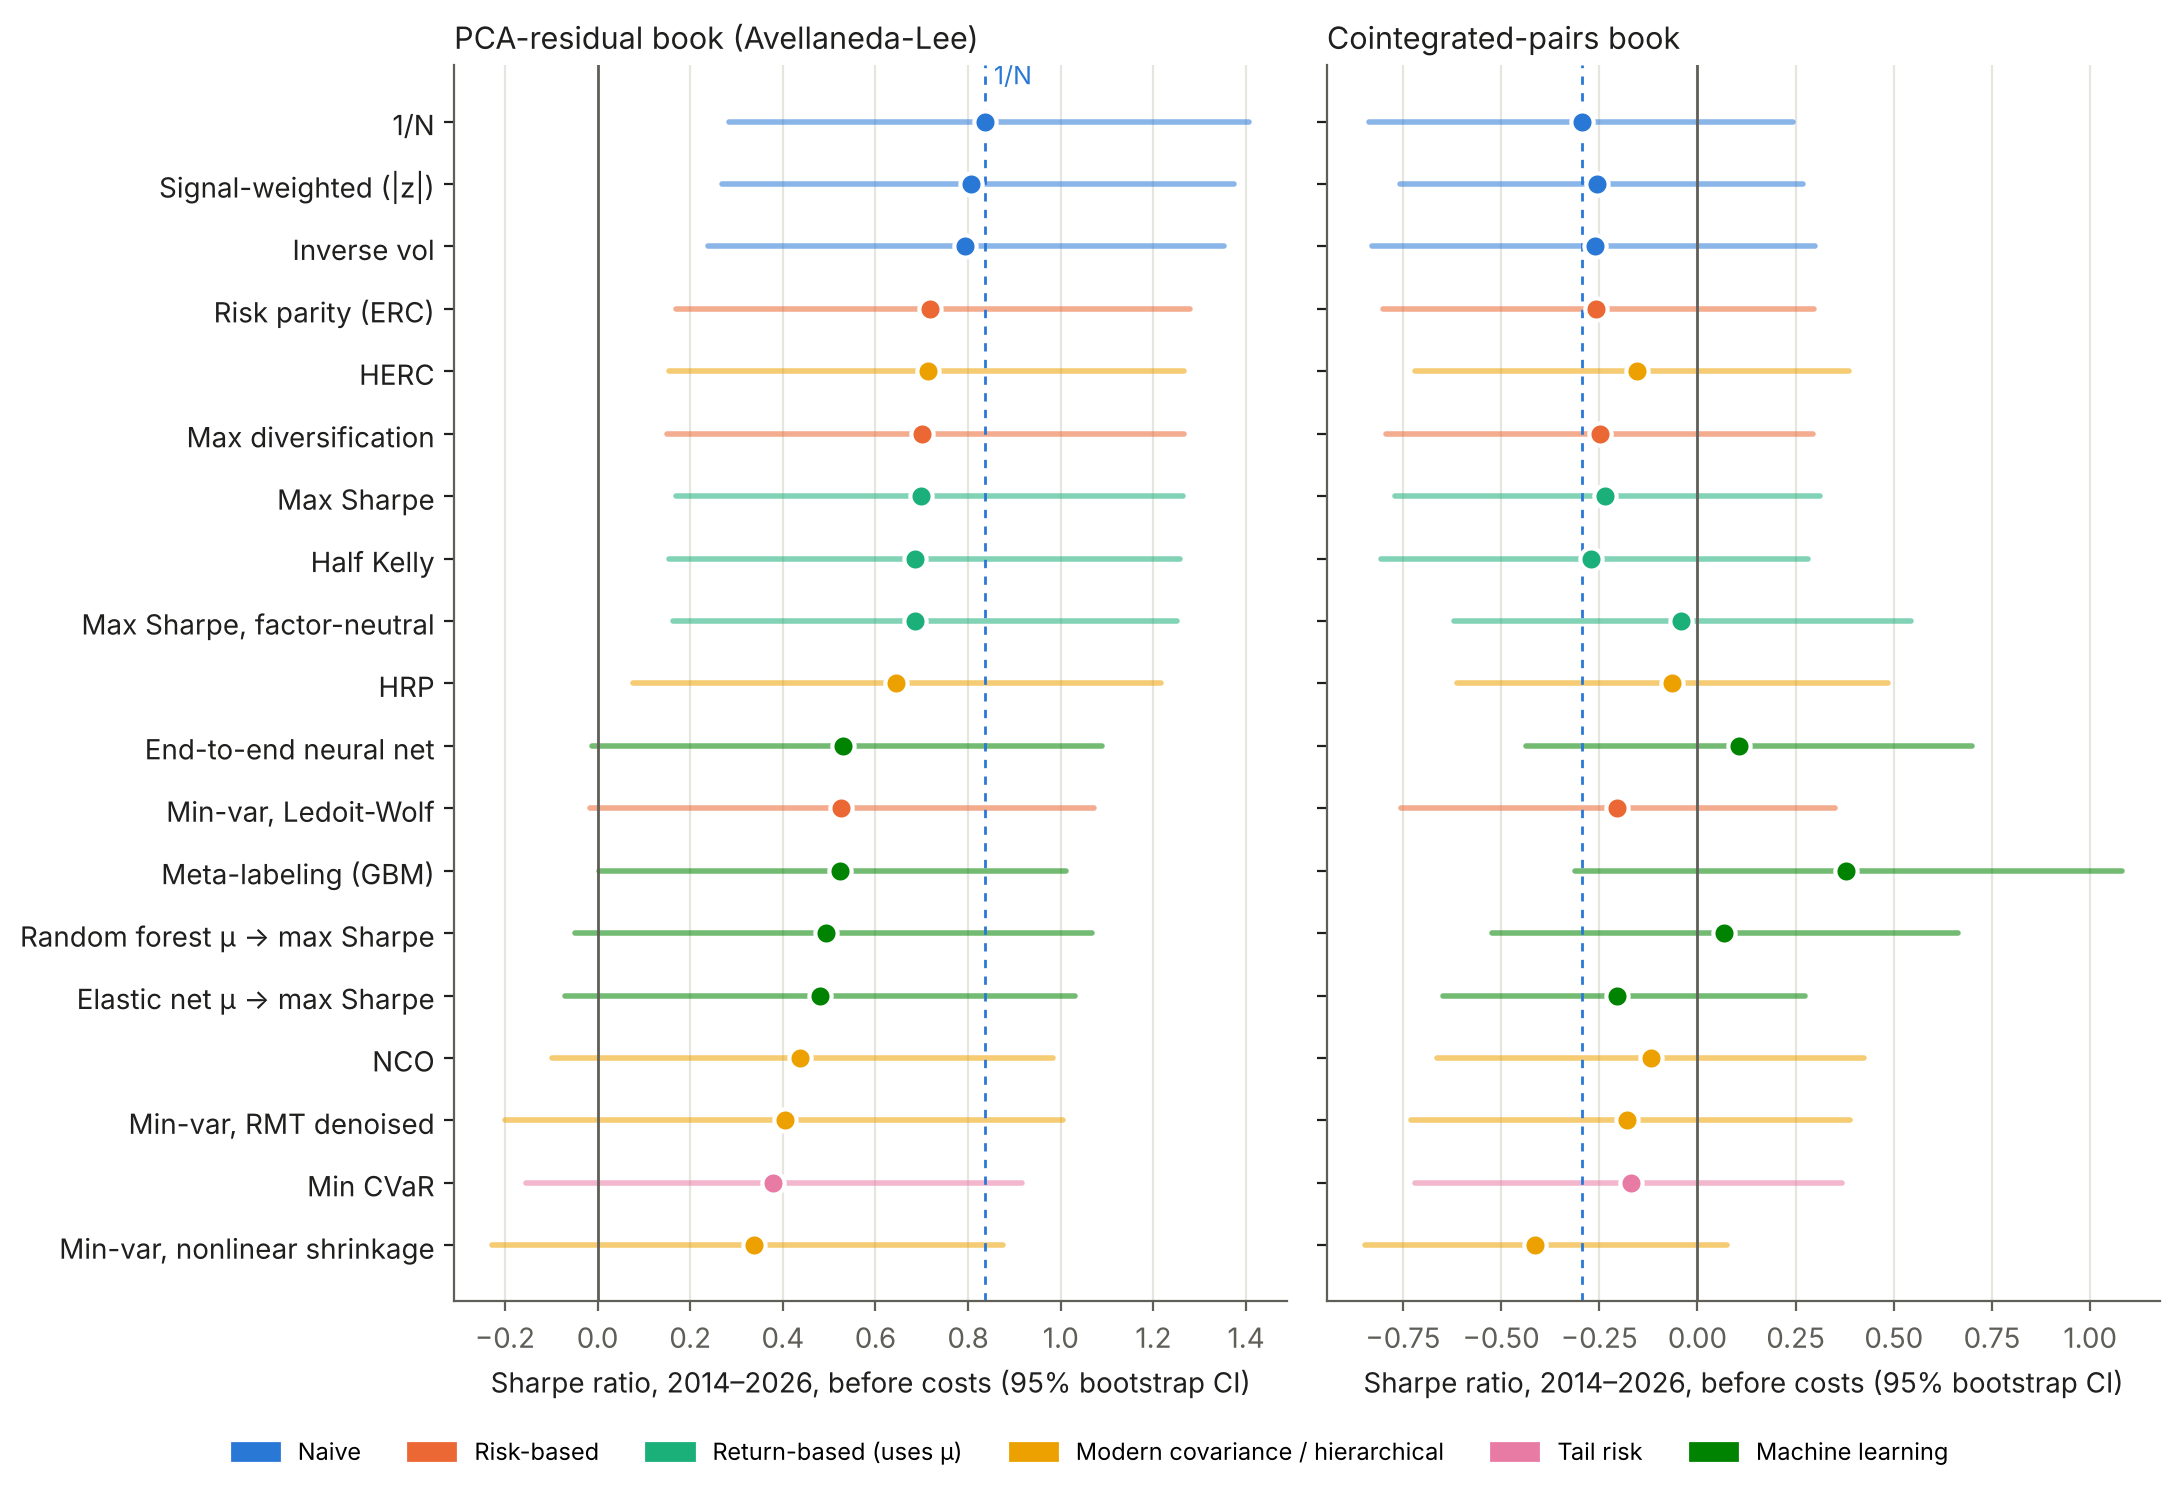

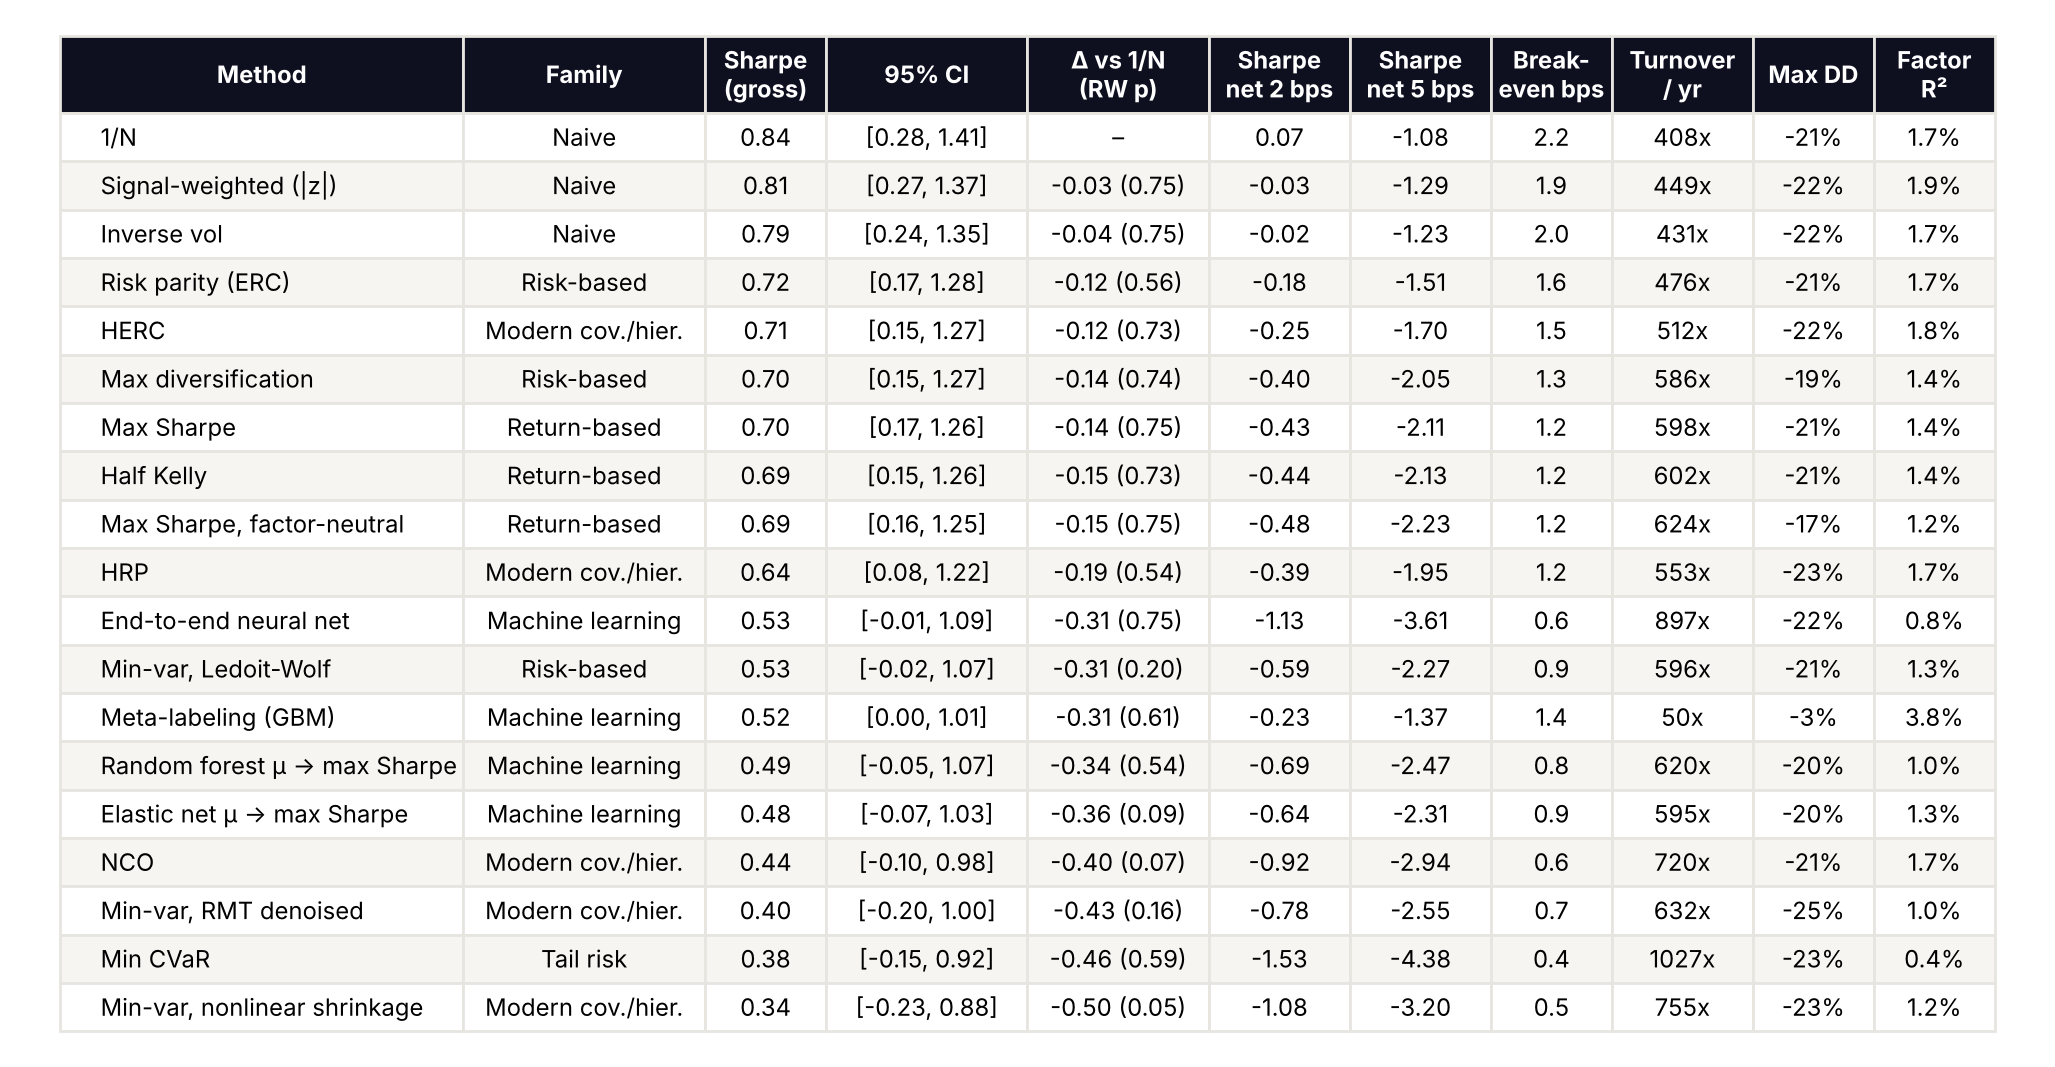

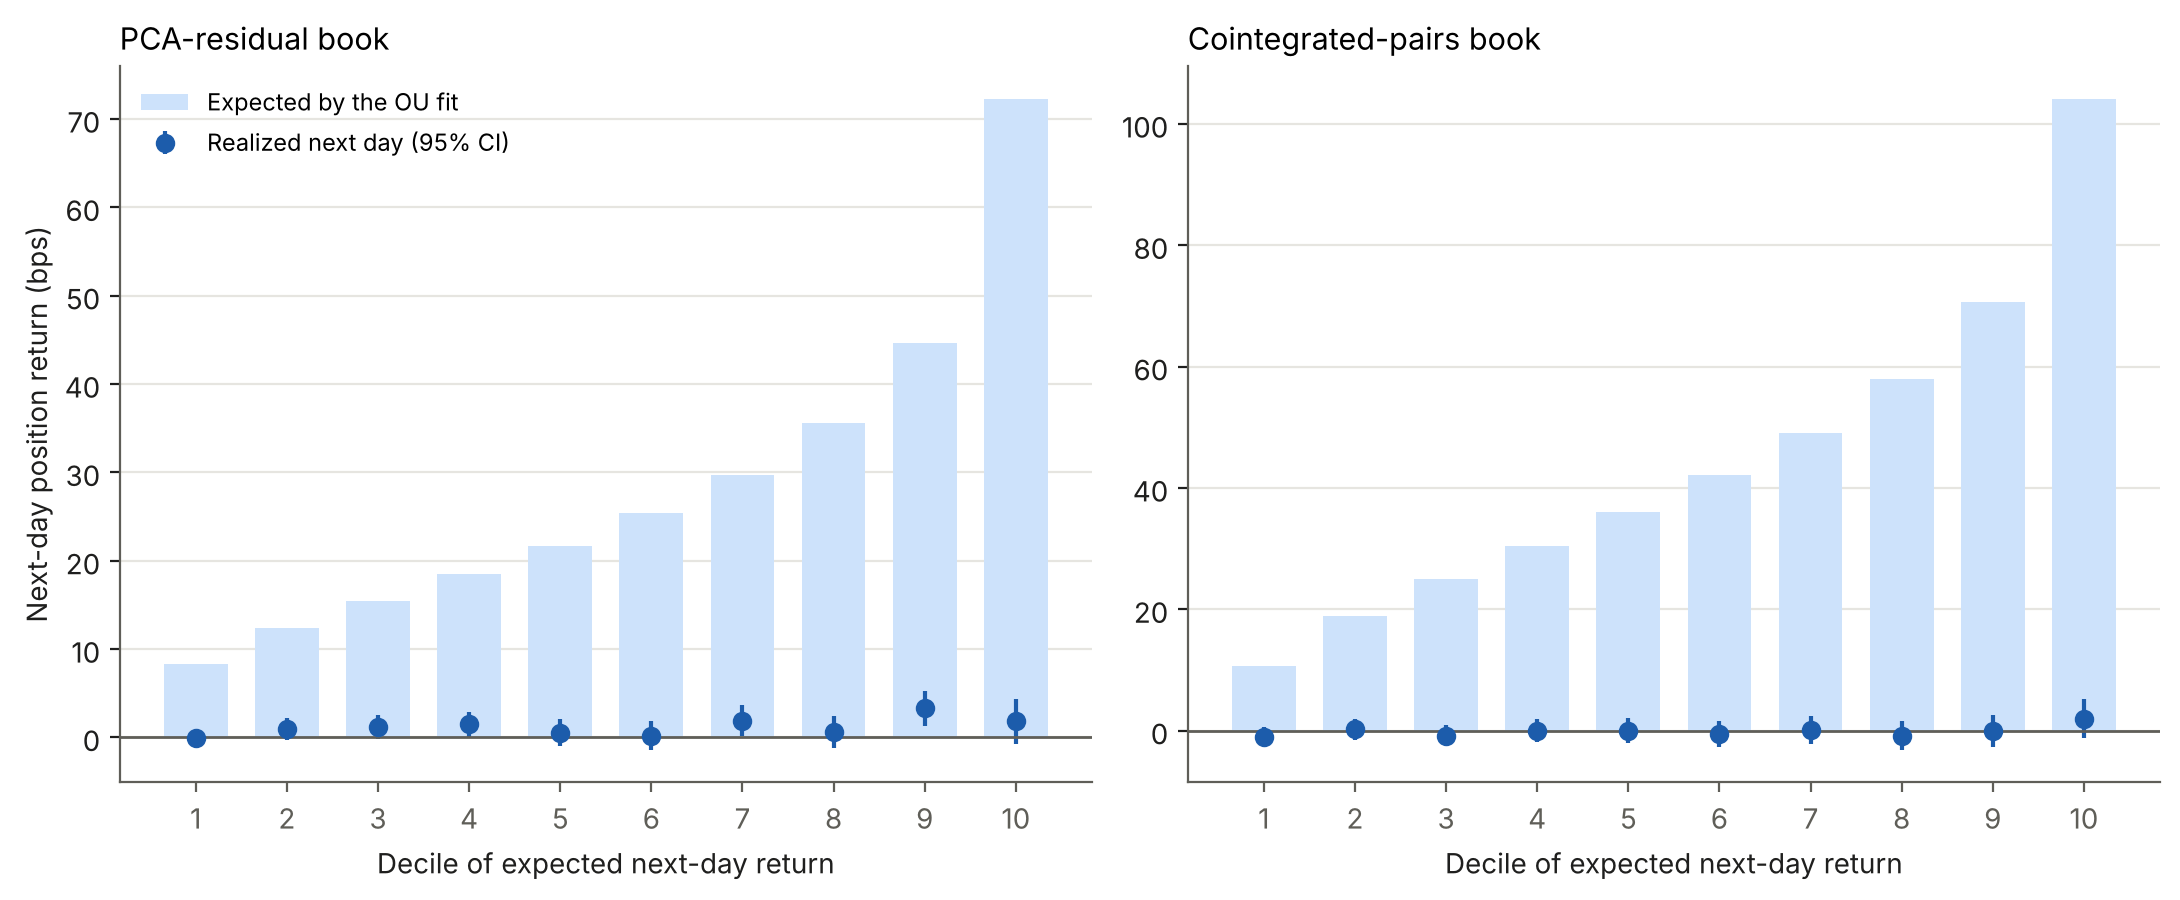

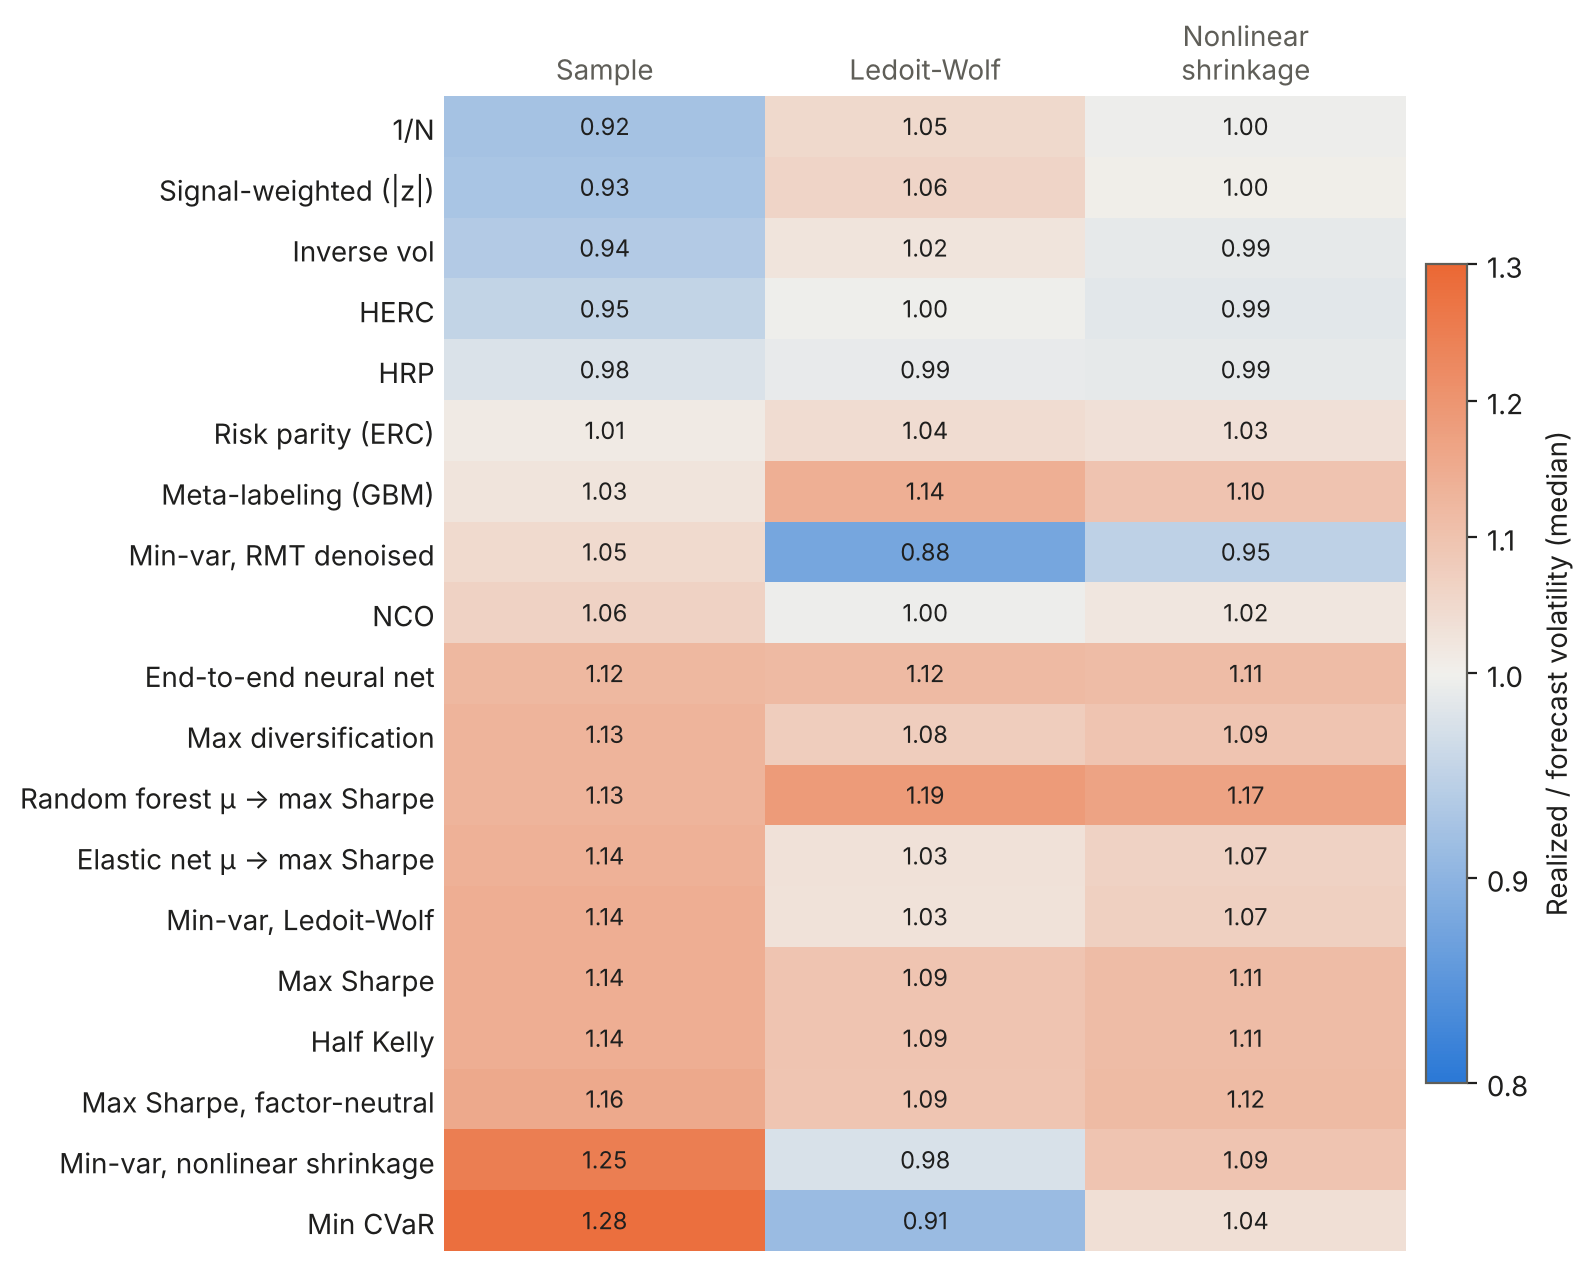

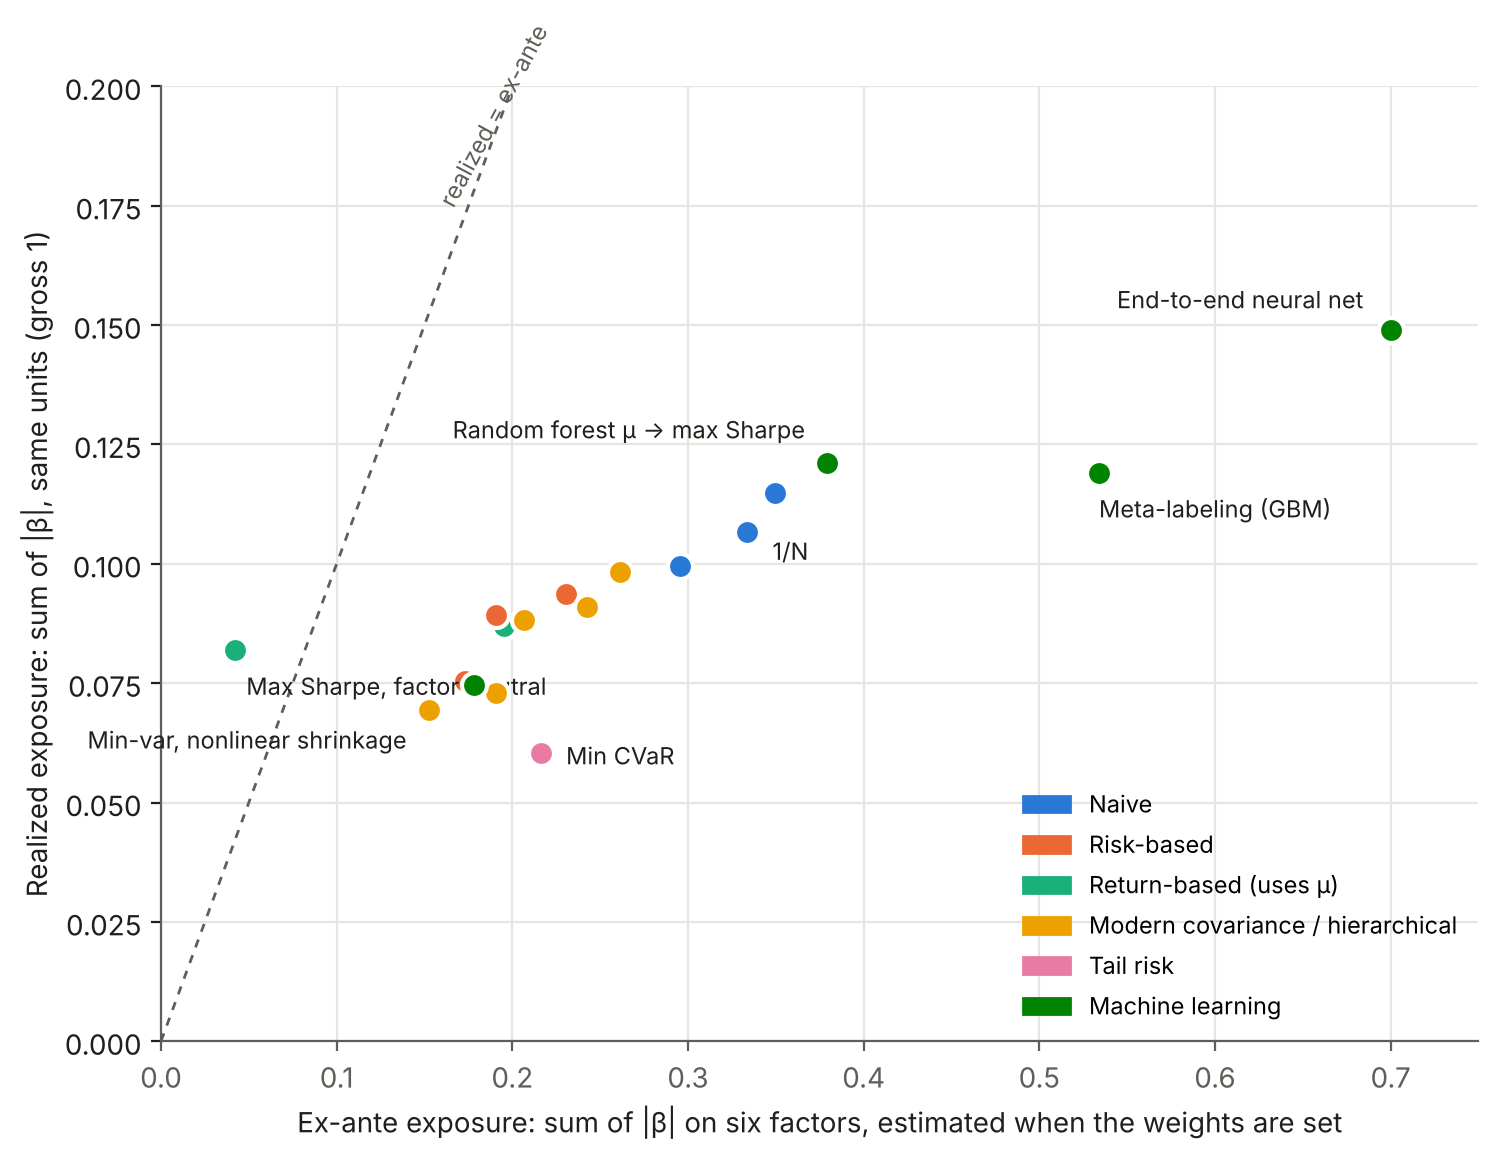

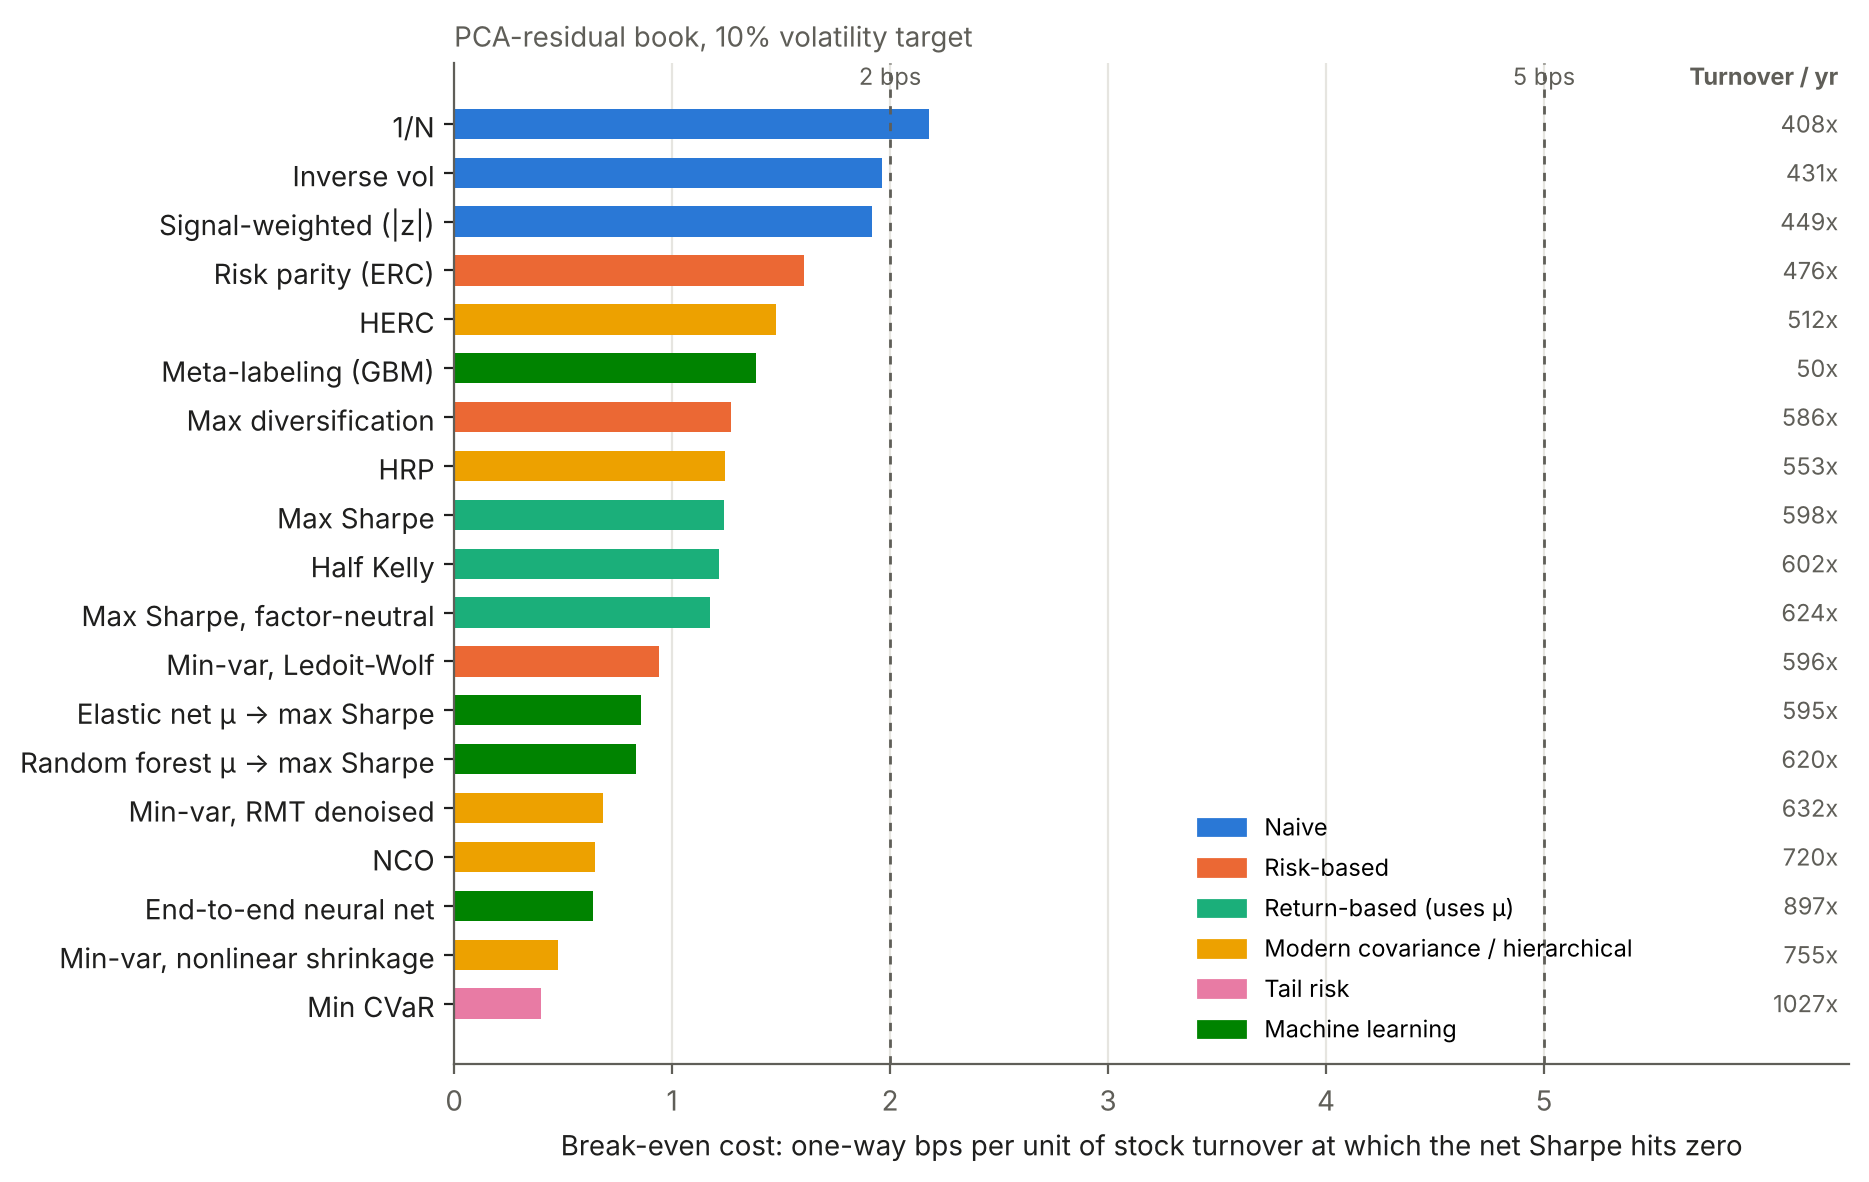

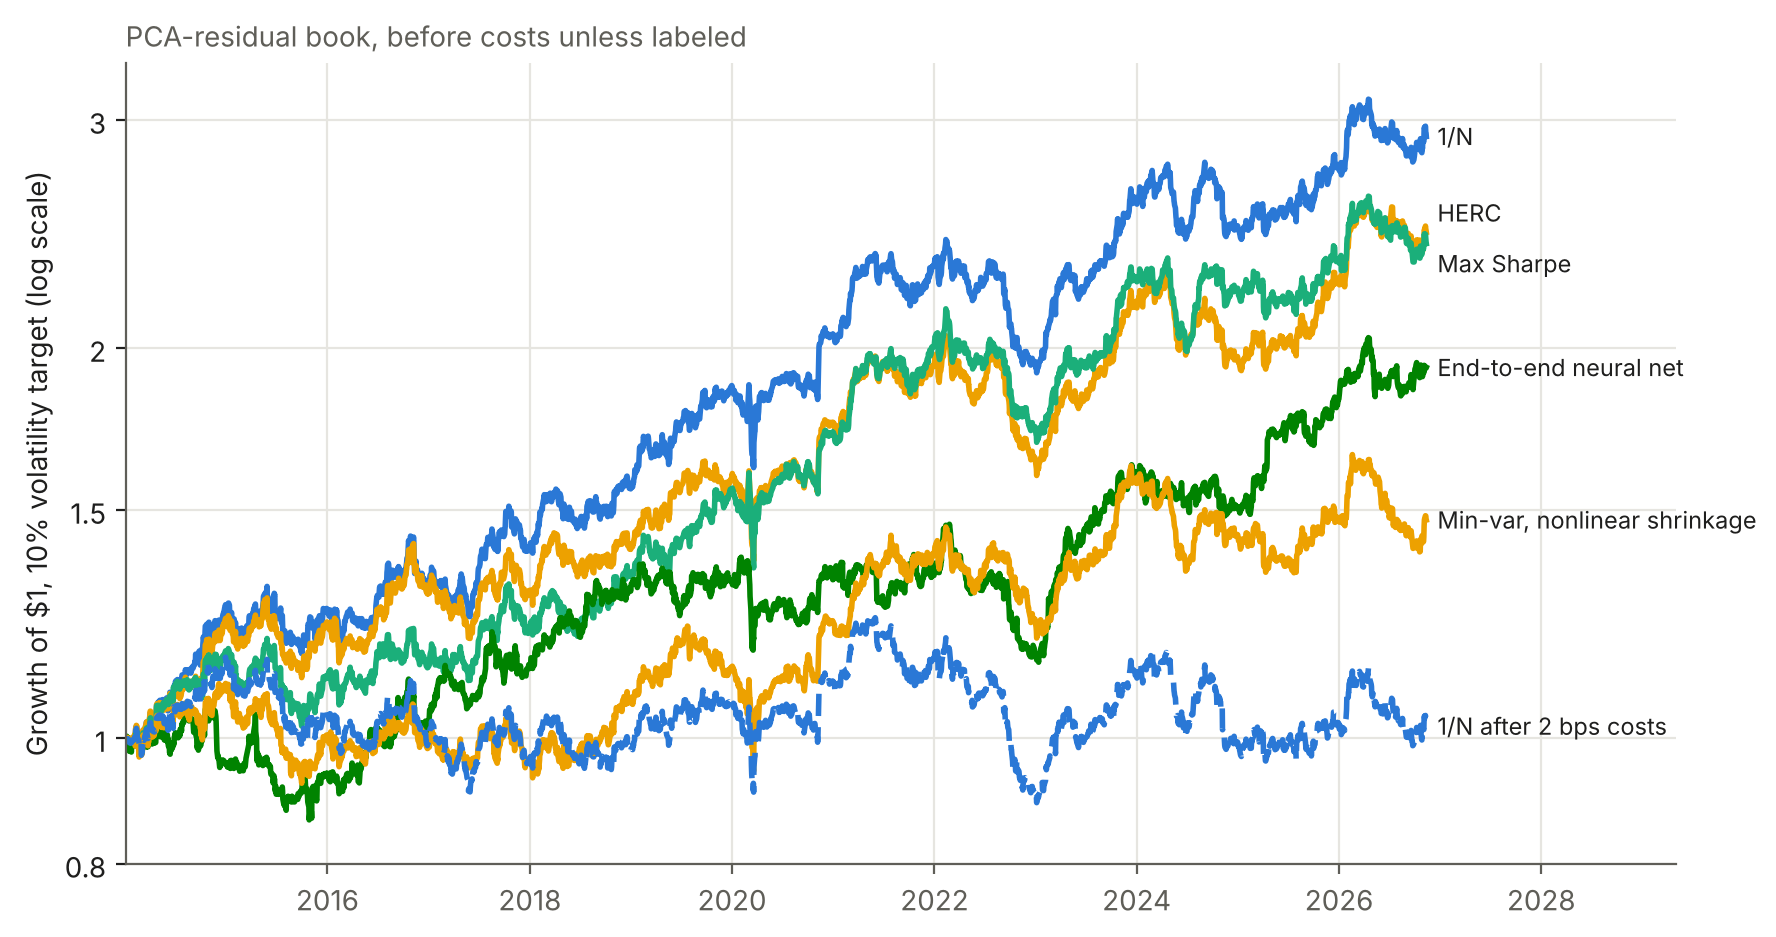

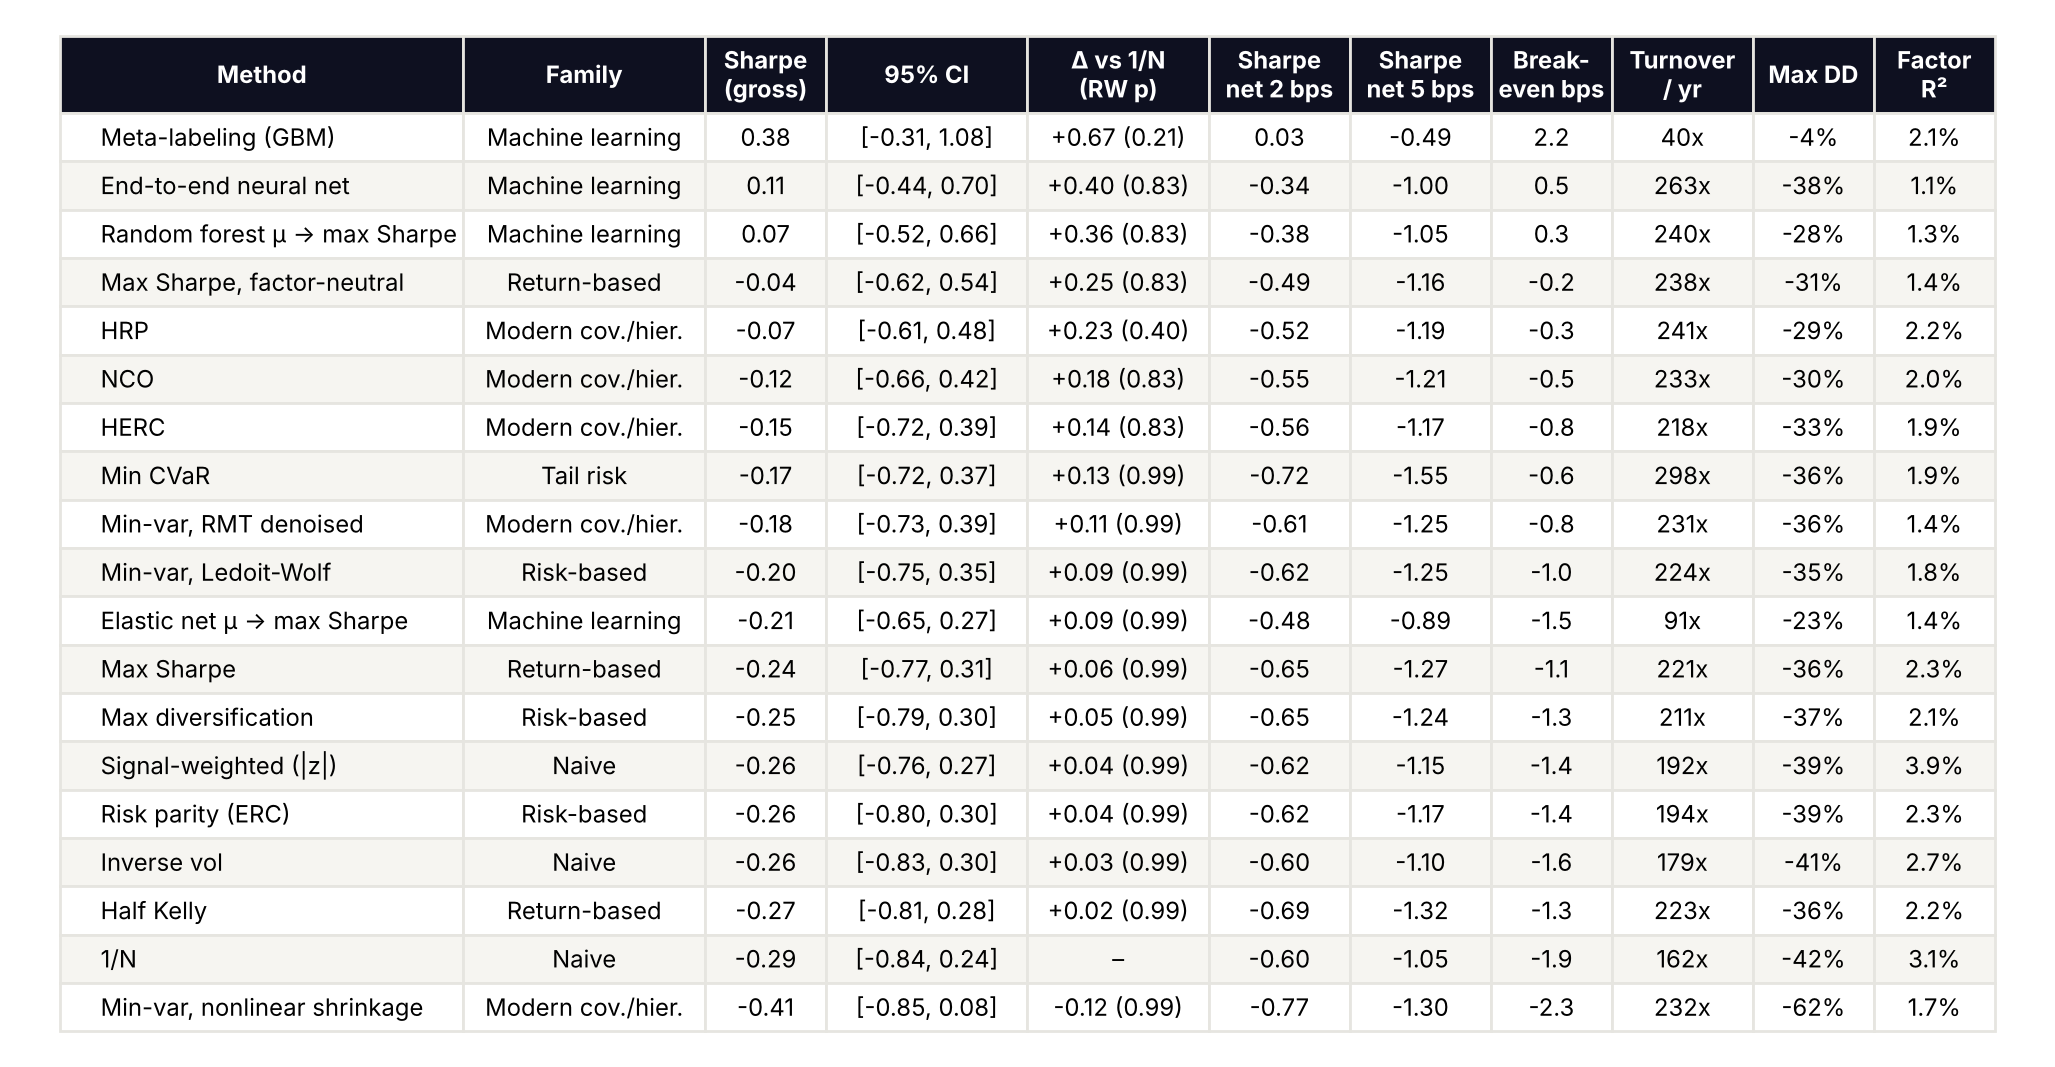

In [22]:
from IPython.display import Image, display
for f in ["fig1_sharpe_ci", "table1_al", "fig4_mu_vs_realized", "fig5_risk_bias", "fig3_neutrality", "fig2_breakeven", "fig6_cumulative", "table2_pairs"]:
    display(Image(f"fig/{f}.png", width=900))